
# 乳酸+谷氨酰胺混合生态位跨癌种 DEG/GSEA：乳腺癌 vs 结直肠癌

目标生态位：`Multi_Axis_Lactate_Glutamine`。比较乳腺癌和结直肠癌中混合代谢生态位相对于各自癌种其他肿瘤生态位的差异表达和功能富集差异。

## 分析设计

每个癌种内部先做：

```text
Multi_Axis_Lactate_Glutamine vs 同癌种其他肿瘤生态位
```

然后再比较两个癌种的 DEG / GSEA signature。

注意：

1. 表达矩阵使用原始全基因 h5ad。
2. 生态位标签使用最终 h5ad 中的 `Level2_Micro_Niche`。
3. 代码只在内存中的 `adata.obs` 增加生态位标签，不会写回或覆盖你的 h5ad。
4. 主结果建议优先使用 `TMCN_genes_excluded`，避免用定义生态位的 TMCN genes 做循环验证。


In [2]:

# =========================================================
# Cell 1: 环境与基础设置
# =========================================================
import os
import re
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse
from scipy.stats import hypergeom, spearmanr, pearsonr

import matplotlib.pyplot as plt


# GPU 选择（保留你的设置）
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
try:
    import seaborn as sns
    HAS_SEABORN = True
except Exception:
    HAS_SEABORN = False
    print("⚠️ 没有检测到 seaborn，部分热图会使用 matplotlib 简化绘制。")

try:
    import gseapy as gp
    HAS_GSEAPY = True
except Exception:
    HAS_GSEAPY = False
    print("⚠️ 没有检测到 gseapy：GSEA prerank 将跳过，但 DEG 和 ORA 仍可运行。")

warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("scanpy:", sc.__version__)
print("gseapy available:", HAS_GSEAPY)


scanpy: 1.9.8
gseapy available: True


In [3]:

# =========================================================
# Cell 2: 分析参数
# =========================================================

ANALYSIS_NAME = "Mixed_Lactate_Glutamine_Niche_Breast_vs_CRC"
TARGET_NICHE = "Multi_Axis_Lactate_Glutamine"

# 表达矩阵来自原始全基因 h5ad；
# 生态位标签来自你的方法最终 h5ad。
# 注意：本 notebook 不会修改或覆盖任何 h5ad 文件。
DATASETS = {
    "Breast_Cancer": {
        "raw_h5ad": "/home/zhangjunyi/xiangmu/nichecompass-main/datasets/Human_breast_cancer/Human_breast_cancer_ViHBC/Human_breast_cancer_integrated.h5ad",
        "niche_h5ad": "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/Human_breast_cancer_ViHBC/SpaCET_And_My/Human_breast_cancer_ViHBC_NicheCompassAndmy_Final.h5ad",
    },
    "Colorectal_Cancer": {
        "raw_h5ad": "/home/zhangjunyi/xiangmu/nichecompass-main/datasets/12_colorectal_cancer_CRC/12_colorectal_cancer_CRC_h5ad/SN048_A121573_Rep1.h5ad",
        "niche_h5ad": "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN048_A121573_Rep1/SpaCET_And_My/SN048_A121573_Rep1_NicheCompassAndmy_Final.h5ad",
    },
}

NICHE_COL = "Level2_Micro_Niche"
HEALTHY_LABELS = ["Healthy_Region"]

OUT_ROOT = Path("/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC")

# GMT 路径：如文件名和本地版本不同，只需要修改这里
GMT_DIR = Path("/home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/GMT/MSigDB")
GMT_FILES = {
    "Hallmark": GMT_DIR / "h.all.v2026.1.Hs.symbols.gmt",
    "Reactome": GMT_DIR / "c2.cp.reactome.v2026.1.Hs.symbols.gmt",
    "Curated_CP": GMT_DIR / "c2.cp.v2026.1.Hs.symbols.gmt",
    "GO_all": GMT_DIR / "c5.all.v2026.1.Hs.symbols.gmt",
    "C6_Oncogenic": GMT_DIR / "c6.all.v2026.1.Hs.symbols.gmt",
    "C7_Immunologic": GMT_DIR / "c7.all.v2026.1.Hs.symbols.gmt",
    "C8_CellType": GMT_DIR / "c8.all.v2026.1.Hs.symbols.gmt",
}

MIN_CASE_SPOTS = 20
MIN_CONTROL_SPOTS = 20
MIN_CELLS = 3
NORMALIZE_TARGET_SUM = 1e4

DEG_FDR_CUTOFF = 0.05
DEG_LOGFC_CUTOFF = 0.25

GMT_MIN_SIZE = 10
GMT_MAX_SIZE = 500
GSEA_PERMUTATION_NUM = 1000
GSEA_FDR_CUTOFF = 0.25
GSEA_TOP_N_TERMS = 40
RANDOM_SEED = 42

ANALYSIS_VARIANTS = [
    "all_genes",
    "TMCN_genes_excluded",
    "current_axis_genes_excluded",
]

# TMCN 定义基因集合：
# 仅用于“排除定义基因”的验证分析；不会修改你的数据。
# 如果你有更完整的 TMCN axis table，可在这里补充。
TMCN_AXIS_GENES = {
    "Lactate": [
        "SLC2A1", "HK2", "PKM", "LDHA", "LDHB",
        "SLC16A1", "SLC16A3", "SLC16A7",
        "HIF1A", "EPAS1", "MYC",
    ],
    "Glutamine": [
        "SLC1A5", "SLC38A1", "SLC38A2", "SLC7A5", "SLC3A2",
        "GLS", "GLS2", "GLUL", "GOT1", "GOT2",
        "MYC", "MTOR",
    ],
    "LPA": [
        "ENPP2", "PLA2G4A", "LPCAT1",
        "LPAR1", "LPAR2", "LPAR3", "LPAR5",
    ],
    "S1P": [
        "SPHK1", "SPHK2", "SGPL1", "SGPP1", "SGPP2",
        "S1PR1", "S1PR2", "S1PR3", "S1PR4", "S1PR5",
    ],
    "PGE2": [
        "PLA2G4A", "PTGS1", "PTGS2", "PTGES",
        "PTGER1", "PTGER2", "PTGER3", "PTGER4",
    ],
}

print("ANALYSIS_NAME:", ANALYSIS_NAME)
print("TARGET_NICHE:", TARGET_NICHE)
print("DATASETS:", list(DATASETS.keys()))
print("OUT_ROOT:", OUT_ROOT)


ANALYSIS_NAME: Mixed_Lactate_Glutamine_Niche_Breast_vs_CRC
TARGET_NICHE: Multi_Axis_Lactate_Glutamine
DATASETS: ['Breast_Cancer', 'Colorectal_Cancer']
OUT_ROOT: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC


In [4]:

# =========================================================
# Cell 3: 工具函数
# =========================================================

def safe_filename(x, max_len=150):
    x = str(x)
    x = re.sub(r"[\\/:*?\"<>|()\[\]{} ,]+", "_", x)
    x = re.sub(r"_+", "_", x).strip("_")
    return x[:max_len] if len(x) > max_len else x


def ensure_dir(path):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    return path


def sample_matrix(M, max_rows=600, max_cols=2500, random_state=0):
    """抽样矩阵，避免将全矩阵转 dense。"""
    rng = np.random.default_rng(random_state)
    n_rows, n_cols = M.shape

    rows = np.arange(n_rows)
    cols = np.arange(n_cols)

    if n_rows > max_rows:
        rows = np.sort(rng.choice(n_rows, size=max_rows, replace=False))
    if n_cols > max_cols:
        cols = np.sort(rng.choice(n_cols, size=max_cols, replace=False))

    sub = M[rows, :][:, cols]
    if sparse.issparse(sub):
        sub = sub.toarray()
    return np.asarray(sub)


def inspect_matrix_for_deg(M, matrix_name="adata.X"):
    """粗略判断矩阵是否像 raw counts / log-normalized / scaled。"""
    sub = sample_matrix(M)
    values = sub[np.isfinite(sub)]
    if values.size == 0:
        return {
            "matrix": matrix_name,
            "min": np.nan,
            "max": np.nan,
            "mean": np.nan,
            "zero_fraction": np.nan,
            "negative_fraction": np.nan,
            "integer_like_fraction_nonzero": np.nan,
            "guess": "invalid",
            "preprocess_action": "cannot_use",
        }

    nonzero = values[values != 0]
    if nonzero.size > 0:
        int_frac = float(np.mean(np.isclose(nonzero, np.round(nonzero), atol=1e-6)))
    else:
        int_frac = np.nan

    min_val = float(np.nanmin(values))
    max_val = float(np.nanmax(values))
    neg_frac = float(np.mean(values < 0))
    zero_frac = float(np.mean(values == 0))

    if neg_frac > 0.01:
        guess = "scaled_or_zscore_like"
        action = "not_recommended"
    elif (not np.isnan(int_frac)) and int_frac > 0.98 and max_val > 20:
        guess = "raw_counts_like"
        action = "normalize_total_log1p"
    elif min_val >= 0 and max_val <= 30 and ((np.isnan(int_frac)) or int_frac < 0.98):
        guess = "log_normalized_like"
        action = "use_as_is"
    elif min_val >= 0 and max_val > 30:
        guess = "positive_large_values"
        action = "normalize_total_log1p"
    else:
        guess = "unknown"
        action = "normalize_total_log1p"

    return {
        "matrix": matrix_name,
        "min": min_val,
        "max": max_val,
        "mean": float(np.nanmean(values)),
        "zero_fraction": zero_frac,
        "negative_fraction": neg_frac,
        "integer_like_fraction_nonzero": int_frac,
        "guess": guess,
        "preprocess_action": action,
    }


def load_raw_expression_with_niche_labels(raw_h5ad_path, niche_h5ad_path, niche_col):
    """
    读取原始全基因 h5ad，并从最终 h5ad 中把生态位标签复制到原始 adata.obs。
    只修改内存对象，不写回任何 h5ad。
    """
    raw_h5ad_path = Path(raw_h5ad_path)
    niche_h5ad_path = Path(niche_h5ad_path)

    if not raw_h5ad_path.exists():
        raise FileNotFoundError(f"原始表达 h5ad 不存在: {raw_h5ad_path}")
    if not niche_h5ad_path.exists():
        raise FileNotFoundError(f"最终生态位 h5ad 不存在: {niche_h5ad_path}")

    print(f"\n📖 读取原始全基因表达矩阵: {raw_h5ad_path}")
    adata_expr = sc.read_h5ad(raw_h5ad_path)
    print(adata_expr)

    print(f"📖 读取最终生态位标签: {niche_h5ad_path}")
    adata_niche = sc.read_h5ad(niche_h5ad_path)
    print(adata_niche)

    if niche_col not in adata_niche.obs.columns:
        raise KeyError(
            f"最终 h5ad 中找不到生态位列 {niche_col}.\n"
            f"当前 obs.columns 为: {list(adata_niche.obs.columns)}"
        )

    common_obs = adata_expr.obs_names.intersection(adata_niche.obs_names)
    print(f"共同 spots 数: {len(common_obs)} / 原始表达 {adata_expr.n_obs} / 最终生态位 {adata_niche.n_obs}")

    if len(common_obs) == 0:
        raise ValueError("两个 h5ad 的 obs_names 没有交集，无法合并生态位标签。")

    adata_expr = adata_expr[common_obs].copy()
    niche_labels = adata_niche.obs.loc[common_obs, niche_col].astype(str)
    adata_expr.obs[niche_col] = niche_labels.values
    adata_expr.var_names_make_unique()

    return adata_expr


def add_case_control_group(adata, target_niche, niche_col, healthy_labels):
    """
    在内存对象中添加 DEG_Group:
    case = 当前目标生态位
    control = 除 Healthy_Region 以外的其他肿瘤生态位
    """
    labels = adata.obs[niche_col].astype(str)

    healthy_set = set([str(x) for x in healthy_labels])
    valid_label_mask = labels.notna() & (~labels.isin(["nan", "None", "NA", "NaN", ""]))
    case_mask = labels.eq(target_niche)
    tumor_like_mask = valid_label_mask & (~labels.isin(healthy_set))
    control_mask = tumor_like_mask & (~case_mask)

    sub = adata[case_mask | control_mask].copy()
    sub.obs["DEG_Group"] = np.where(
        sub.obs[niche_col].astype(str).eq(target_niche),
        "case",
        "control"
    )
    sub.obs["DEG_Group"] = pd.Categorical(
        sub.obs["DEG_Group"],
        categories=["case", "control"],
        ordered=True
    )

    summary = {
        "total_spots_after_merge": adata.n_obs,
        "case_spots": int(case_mask.sum()),
        "control_spots": int(control_mask.sum()),
        "healthy_or_excluded_spots": int((~(case_mask | control_mask)).sum()),
        "all_niche_counts": labels.value_counts().to_dict(),
        "control_niche_counts": labels[control_mask].value_counts().to_dict(),
    }

    return sub, summary


def preprocess_for_deg(adata, min_cells=3, target_sum=1e4):
    """
    为 Wilcoxon DEG 准备表达矩阵。
    如果 adata.X 像 raw counts，则 normalize_total + log1p；
    如果像 log-normalized，则直接使用。
    """
    adata = adata.copy()
    sc.pp.filter_genes(adata, min_cells=min_cells)

    matrix_info_before = inspect_matrix_for_deg(adata.X, matrix_name="adata.X_after_filter_genes")

    action = matrix_info_before["preprocess_action"]
    if action == "normalize_total_log1p":
        print("🔧 adata.X 看起来不是 log-normalized：执行 normalize_total + log1p")
        sc.pp.normalize_total(adata, target_sum=target_sum)
        sc.pp.log1p(adata)
        preprocess_note = "normalize_total_log1p"
    elif action == "use_as_is":
        print("✅ adata.X 看起来像 log-normalized：直接用于 DEG")
        preprocess_note = "use_as_is"
    else:
        print(f"⚠️ 矩阵判断为 {matrix_info_before['guess']}，仍尝试 normalize_total + log1p 后用于 DEG")
        sc.pp.normalize_total(adata, target_sum=target_sum)
        sc.pp.log1p(adata)
        preprocess_note = "normalize_total_log1p_due_to_unclear_matrix"

    matrix_info_after = inspect_matrix_for_deg(adata.X, matrix_name="adata.X_for_DEG")

    return adata, matrix_info_before, matrix_info_after, preprocess_note


def run_scanpy_wilcoxon_deg(adata, groupby="DEG_Group", case_group="case", control_group="control"):
    """运行 scanpy Wilcoxon DEG。"""
    if groupby not in adata.obs.columns:
        raise KeyError(f"adata.obs 中找不到 {groupby}")

    group_counts = adata.obs[groupby].value_counts()
    print("DEG group counts:")
    print(group_counts)

    if case_group not in group_counts or control_group not in group_counts:
        raise ValueError("case/control 分组不完整，无法 DEG。")

    sc.tl.rank_genes_groups(
        adata,
        groupby=groupby,
        groups=[case_group],
        reference=control_group,
        method="wilcoxon",
        use_raw=False,
        pts=True,
        corr_method="benjamini-hochberg"
    )

    deg = sc.get.rank_genes_groups_df(adata, group=case_group)
    deg = deg.rename(columns={"names": "gene"})
    deg["case_group"] = case_group
    deg["control_group"] = control_group
    deg["comparison"] = f"{case_group}_vs_{control_group}"

    for col in ["logfoldchanges", "scores", "pvals", "pvals_adj"]:
        if col not in deg.columns:
            deg[col] = np.nan

    return deg


def add_rank_score_for_gsea(deg_df):
    """构建 GSEA prerank 排序分数。"""
    df = deg_df.copy()
    df["gene"] = df["gene"].astype(str)

    lfc = pd.to_numeric(df["logfoldchanges"], errors="coerce").fillna(0.0)
    padj = pd.to_numeric(df["pvals_adj"], errors="coerce").fillna(1.0)
    padj = padj.clip(lower=1e-300, upper=1.0)

    df["rank_score"] = np.sign(lfc) * np.abs(lfc) * (-np.log10(padj))
    df = df.sort_values("rank_score", key=lambda x: np.abs(x), ascending=False)
    df = df.drop_duplicates(subset=["gene"], keep="first")
    df = df[["gene", "rank_score"] + [c for c in df.columns if c not in ["gene", "rank_score"]]]

    return df


def parse_gmt(gmt_path, universe=None, min_size=10, max_size=500):
    """读取 GMT 文件为 dict: pathway -> set(genes)。"""
    gene_sets = {}
    gmt_path = Path(gmt_path)

    if not gmt_path.exists():
        print(f"⚠️ GMT 不存在，跳过: {gmt_path}")
        return gene_sets

    universe = set(universe) if universe is not None else None

    with open(gmt_path, "r") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) < 3:
                continue
            term = parts[0]
            genes = set([g for g in parts[2:] if g])
            if universe is not None:
                genes = genes & universe
            if min_size <= len(genes) <= max_size:
                gene_sets[term] = genes

    return gene_sets


def bh_fdr(pvals):
    """Benjamini-Hochberg FDR，不依赖 statsmodels。"""
    pvals = np.asarray(pvals, dtype=float)
    n = len(pvals)
    if n == 0:
        return pvals
    order = np.argsort(pvals)
    ranked = pvals[order]
    q = ranked * n / (np.arange(n) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out = np.empty(n, dtype=float)
    out[order] = q
    return out


def run_ora_for_direction(deg_df, gene_sets, direction="up", fdr_cutoff=0.05, logfc_cutoff=0.25):
    """
    ORA:
    up   = case 相对 control 上调基因
    down = case 相对 control 下调基因
    """
    df = deg_df.copy()
    df["pvals_adj"] = pd.to_numeric(df["pvals_adj"], errors="coerce").fillna(1.0)
    df["logfoldchanges"] = pd.to_numeric(df["logfoldchanges"], errors="coerce").fillna(0.0)

    universe = set(df["gene"].astype(str))
    if direction == "up":
        query = set(df.loc[(df["pvals_adj"] < fdr_cutoff) & (df["logfoldchanges"] > logfc_cutoff), "gene"].astype(str))
    elif direction == "down":
        query = set(df.loc[(df["pvals_adj"] < fdr_cutoff) & (df["logfoldchanges"] < -logfc_cutoff), "gene"].astype(str))
    else:
        raise ValueError("direction 必须是 up 或 down")

    M = len(universe)
    N = len(query)
    records = []

    if N == 0:
        return pd.DataFrame(columns=[
            "Term", "direction", "overlap", "query_size", "term_size", "universe_size",
            "pvalue", "fdr", "overlap_genes"
        ])

    for term, genes in gene_sets.items():
        genes = set(genes) & universe
        n = len(genes)
        if n == 0:
            continue
        overlap_genes = sorted(query & genes)
        k = len(overlap_genes)
        if k == 0:
            continue

        pval = hypergeom.sf(k - 1, M, n, N)
        records.append({
            "Term": term,
            "direction": direction,
            "overlap": k,
            "query_size": N,
            "term_size": n,
            "universe_size": M,
            "pvalue": pval,
            "overlap_genes": ";".join(overlap_genes),
        })

    res = pd.DataFrame(records)
    if len(res) == 0:
        return pd.DataFrame(columns=[
            "Term", "direction", "overlap", "query_size", "term_size", "universe_size",
            "pvalue", "fdr", "overlap_genes"
        ])

    res["fdr"] = bh_fdr(res["pvalue"].values)
    res = res.sort_values(["fdr", "pvalue", "overlap"], ascending=[True, True, False])
    return res


def run_gsea_prerank(deg_df, gene_sets, collection_name, outdir, permutation_num=1000, seed=42):
    """运行 gseapy.prerank。若没有 gseapy 或 gene_sets 为空，则返回空表。"""
    if not HAS_GSEAPY:
        return pd.DataFrame()

    if len(gene_sets) == 0:
        return pd.DataFrame()

    ranked = add_rank_score_for_gsea(deg_df)
    rnk = ranked[["gene", "rank_score"]].dropna()
    rnk = rnk.replace([np.inf, -np.inf], np.nan).dropna()

    if rnk.shape[0] < 50:
        print(f"⚠️ 可用于 GSEA 的基因过少: {rnk.shape[0]}")
        return pd.DataFrame()

    if rnk["rank_score"].nunique() < 10:
        print("⚠️ rank_score 唯一值过少，跳过 GSEA。")
        return pd.DataFrame()

    outdir = ensure_dir(outdir)

    try:
        pre_res = gp.prerank(
            rnk=rnk,
            gene_sets=gene_sets,
            outdir=None,
            min_size=10,
            max_size=500,
            permutation_num=permutation_num,
            seed=seed,
            threads=4,
            verbose=False
        )
    except TypeError:
        pre_res = gp.prerank(
            rnk=rnk,
            gene_sets=gene_sets,
            outdir=None,
            min_size=10,
            max_size=500,
            permutation_num=permutation_num,
            seed=seed,
            processes=4,
            verbose=False
        )

    res = pre_res.res2d.copy()
    if res is None or len(res) == 0:
        return pd.DataFrame()

    rename_map = {
        "FDR q-val": "FDR",
        "NOM p-val": "pvalue",
        "Lead_genes": "leading_edge_genes",
        "NES": "NES",
        "ES": "ES",
        "Term": "Term",
    }
    res = res.rename(columns={k: v for k, v in rename_map.items() if k in res.columns})

    if "Term" not in res.columns and res.index.name is not None:
        res = res.reset_index().rename(columns={res.index.name: "Term"})
    elif "Term" not in res.columns:
        res = res.reset_index().rename(columns={"index": "Term"})

    for col in ["NES", "FDR", "pvalue", "ES"]:
        if col not in res.columns:
            res[col] = np.nan

    if "leading_edge_genes" not in res.columns:
        res["leading_edge_genes"] = ""

    res["collection"] = collection_name
    res = res.sort_values(["FDR", "NES"], ascending=[True, False])
    return res


def get_tmc_genes_for_variant(target_niche, tmcn_axis_genes):
    """根据目标生态位确定 current_axis_genes_excluded 的基因集合。"""
    target_upper = target_niche.upper()
    genes = set()

    if "LACTATE" in target_upper:
        genes |= set(tmcn_axis_genes.get("Lactate", []))
    if "GLUTAMINE" in target_upper:
        genes |= set(tmcn_axis_genes.get("Glutamine", []))
    if "LPA" in target_upper:
        genes |= set(tmcn_axis_genes.get("LPA", []))
    if "S1P" in target_upper:
        genes |= set(tmcn_axis_genes.get("S1P", []))
    if "PGE2" in target_upper:
        genes |= set(tmcn_axis_genes.get("PGE2", []))

    return set([g.upper() for g in genes])


def filter_deg_by_variant(deg_df, variant_name, all_tmcn_genes, current_axis_genes):
    """生成 all_genes / TMCN_genes_excluded / current_axis_genes_excluded 三版 DEG 表。"""
    df = deg_df.copy()
    gene_upper = df["gene"].astype(str).str.upper()

    if variant_name == "all_genes":
        return df

    if variant_name == "TMCN_genes_excluded":
        return df.loc[~gene_upper.isin(all_tmcn_genes)].copy()

    if variant_name == "current_axis_genes_excluded":
        return df.loc[~gene_upper.isin(current_axis_genes)].copy()

    raise ValueError(f"未知 variant_name: {variant_name}")


def summarize_deg(deg_df, fdr_cutoff=0.05, logfc_cutoff=0.25):
    df = deg_df.copy()
    df["pvals_adj"] = pd.to_numeric(df["pvals_adj"], errors="coerce").fillna(1.0)
    df["logfoldchanges"] = pd.to_numeric(df["logfoldchanges"], errors="coerce").fillna(0.0)

    return {
        "n_genes_tested": int(df.shape[0]),
        "n_up": int(((df["pvals_adj"] < fdr_cutoff) & (df["logfoldchanges"] > logfc_cutoff)).sum()),
        "n_down": int(((df["pvals_adj"] < fdr_cutoff) & (df["logfoldchanges"] < -logfc_cutoff)).sum()),
        "n_sig_total": int((df["pvals_adj"] < fdr_cutoff).sum()),
    }


def compare_two_deg_tables(deg_a, deg_b, name_a, name_b, outdir, variant_name, fdr_cutoff=0.05, logfc_cutoff=0.25):
    """比较两个癌种的同一生态位 DEG signature。"""
    outdir = ensure_dir(outdir)

    a = deg_a.copy()
    b = deg_b.copy()

    keep_cols = ["gene", "logfoldchanges", "pvals_adj", "scores"]
    for c in keep_cols:
        if c not in a.columns:
            a[c] = np.nan
        if c not in b.columns:
            b[c] = np.nan

    m = pd.merge(
        a[keep_cols],
        b[keep_cols],
        on="gene",
        how="inner",
        suffixes=(f"_{name_a}", f"_{name_b}")
    )

    if len(m) == 0:
        print("⚠️ 两个癌种没有共同基因，无法比较 DEG。")
        return m, {}

    lfc_a = pd.to_numeric(m[f"logfoldchanges_{name_a}"], errors="coerce").fillna(0.0)
    lfc_b = pd.to_numeric(m[f"logfoldchanges_{name_b}"], errors="coerce").fillna(0.0)
    fdr_a = pd.to_numeric(m[f"pvals_adj_{name_a}"], errors="coerce").fillna(1.0)
    fdr_b = pd.to_numeric(m[f"pvals_adj_{name_b}"], errors="coerce").fillna(1.0)

    up_a = (fdr_a < fdr_cutoff) & (lfc_a > logfc_cutoff)
    up_b = (fdr_b < fdr_cutoff) & (lfc_b > logfc_cutoff)
    down_a = (fdr_a < fdr_cutoff) & (lfc_a < -logfc_cutoff)
    down_b = (fdr_b < fdr_cutoff) & (lfc_b < -logfc_cutoff)

    category = np.full(len(m), "not_significant_or_weak", dtype=object)
    category[up_a & up_b] = "conserved_up"
    category[down_a & down_b] = "conserved_down"
    category[up_a & (~up_b)] = f"{name_a}_specific_up"
    category[up_b & (~up_a)] = f"{name_b}_specific_up"
    category[down_a & (~down_b)] = f"{name_a}_specific_down"
    category[down_b & (~down_a)] = f"{name_b}_specific_down"
    category[(up_a & down_b) | (down_a & up_b)] = "opposite_direction"

    m["signature_category"] = category
    m.to_csv(outdir / f"DEG_cross_cancer_merged_{variant_name}.csv", index=False)

    valid = np.isfinite(lfc_a) & np.isfinite(lfc_b)
    if valid.sum() > 2:
        pearson_r, pearson_p = pearsonr(lfc_a[valid], lfc_b[valid])
        spearman_r, spearman_p = spearmanr(lfc_a[valid], lfc_b[valid])
    else:
        pearson_r = pearson_p = spearman_r = spearman_p = np.nan

    summary = {
        "variant": variant_name,
        "n_shared_genes": int(len(m)),
        "pearson_logFC_r": float(pearson_r),
        "pearson_logFC_p": float(pearson_p),
        "spearman_logFC_r": float(spearman_r),
        "spearman_logFC_p": float(spearman_p),
        "conserved_up": int((m["signature_category"] == "conserved_up").sum()),
        "conserved_down": int((m["signature_category"] == "conserved_down").sum()),
        "opposite_direction": int((m["signature_category"] == "opposite_direction").sum()),
        f"{name_a}_specific_up": int((m["signature_category"] == f"{name_a}_specific_up").sum()),
        f"{name_b}_specific_up": int((m["signature_category"] == f"{name_b}_specific_up").sum()),
    }

    pd.DataFrame([summary]).to_csv(outdir / f"DEG_cross_cancer_summary_{variant_name}.csv", index=False)

    fig, ax = plt.subplots(figsize=(5.2, 5.0), dpi=300)
    ax.scatter(lfc_a, lfc_b, s=8, alpha=0.35)
    ax.axhline(0, linewidth=1)
    ax.axvline(0, linewidth=1)
    ax.set_xlabel(f"{name_a} logFC\ncase niche vs other tumor niches")
    ax.set_ylabel(f"{name_b} logFC\ncase niche vs other tumor niches")
    ax.set_title(f"Cross-cancer DEG signature correlation\n{variant_name}\nPearson r={pearson_r:.3f}, Spearman r={spearman_r:.3f}")
    plt.tight_layout()
    fig.savefig(outdir / f"DEG_logFC_scatter_{variant_name}.png", bbox_inches="tight")
    fig.savefig(outdir / f"DEG_logFC_scatter_{variant_name}.pdf", bbox_inches="tight")
    plt.show()

    return m, summary


def compare_gsea_results(gsea_dict, dataset_names, outdir, variant_name, fdr_cutoff=0.25, top_n_terms=40):
    """
    比较两个癌种 GSEA NES。

    修正版：
    1. 强制 NES / FDR 转 float，避免 seaborn heatmap 报 dtype object 错误；
    2. 横轴名称简化为 Breast / CRC / Prostate，避免标签重叠；
    3. 加宽图像，提高可读性；
    4. 适当缩小 pathway 字体；
    5. 保存跨癌种 GSEA merged 表、category summary、NES heatmap。
    """

    outdir = ensure_dir(outdir)

    if len(dataset_names) != 2:
        raise ValueError("当前函数设计为两个癌种比较。")

    name_a, name_b = dataset_names
    gsea_a = gsea_dict.get(name_a, pd.DataFrame()).copy()
    gsea_b = gsea_dict.get(name_b, pd.DataFrame()).copy()

    if len(gsea_a) == 0 or len(gsea_b) == 0:
        print(f"⚠️ {variant_name}: 至少一个癌种没有 GSEA 结果，跳过 GSEA 跨癌种比较。")
        return pd.DataFrame(), pd.DataFrame()

    # ---------------------------------------------------------
    # 1. 检查并标准化必要列
    # ---------------------------------------------------------
    for df in [gsea_a, gsea_b]:
        for col in ["Term", "collection", "NES", "FDR"]:
            if col not in df.columns:
                df[col] = np.nan

        df["Term"] = df["Term"].astype(str)
        df["collection"] = df["collection"].astype(str)
        df["NES"] = pd.to_numeric(df["NES"], errors="coerce")
        df["FDR"] = pd.to_numeric(df["FDR"], errors="coerce")

    key_cols = ["collection", "Term"]

    # ---------------------------------------------------------
    # 2. 合并两个癌种的 GSEA 结果
    # ---------------------------------------------------------
    m = pd.merge(
        gsea_a[key_cols + ["NES", "FDR"]],
        gsea_b[key_cols + ["NES", "FDR"]],
        on=key_cols,
        how="inner",
        suffixes=(f"_{name_a}", f"_{name_b}")
    )

    if len(m) == 0:
        print("⚠️ 两个癌种没有共同 pathway term，无法比较 GSEA。")
        return m, pd.DataFrame()

    # ---------------------------------------------------------
    # 3. 关键修复：merge 后再次强制 NES / FDR 转 float
    # ---------------------------------------------------------
    numeric_cols = [
        f"NES_{name_a}",
        f"NES_{name_b}",
        f"FDR_{name_a}",
        f"FDR_{name_b}",
    ]

    for col in numeric_cols:
        m[col] = pd.to_numeric(m[col], errors="coerce")

    before_n = len(m)
    m = m.dropna(subset=[f"NES_{name_a}", f"NES_{name_b}"]).copy()
    after_n = len(m)

    if after_n < before_n:
        print(f"⚠️ 删除 NES 缺失 pathway: {before_n - after_n} 条")

    if len(m) == 0:
        print("⚠️ NES 全部缺失，无法绘制 GSEA heatmap。")
        return m, pd.DataFrame()

    # ---------------------------------------------------------
    # 4. pathway 分类
    # ---------------------------------------------------------
    m["abs_max_NES"] = m[[f"NES_{name_a}", f"NES_{name_b}"]].abs().max(axis=1)
    m["min_FDR"] = m[[f"FDR_{name_a}", f"FDR_{name_b}"]].min(axis=1)

    sig_a_up = (m[f"FDR_{name_a}"] < fdr_cutoff) & (m[f"NES_{name_a}"] > 0)
    sig_b_up = (m[f"FDR_{name_b}"] < fdr_cutoff) & (m[f"NES_{name_b}"] > 0)

    sig_a_down = (m[f"FDR_{name_a}"] < fdr_cutoff) & (m[f"NES_{name_a}"] < 0)
    sig_b_down = (m[f"FDR_{name_b}"] < fdr_cutoff) & (m[f"NES_{name_b}"] < 0)

    category = np.full(len(m), "not_significant_or_weak", dtype=object)

    category[sig_a_up & sig_b_up] = "conserved_up_pathway"
    category[sig_a_down & sig_b_down] = "conserved_down_pathway"

    category[sig_a_up & (~sig_b_up)] = f"{name_a}_specific_up_pathway"
    category[sig_b_up & (~sig_a_up)] = f"{name_b}_specific_up_pathway"

    category[sig_a_down & (~sig_b_down)] = f"{name_a}_specific_down_pathway"
    category[sig_b_down & (~sig_a_down)] = f"{name_b}_specific_down_pathway"

    category[(sig_a_up & sig_b_down) | (sig_a_down & sig_b_up)] = "opposite_direction_pathway"

    m["pathway_category"] = category

    m = m.sort_values(["min_FDR", "abs_max_NES"], ascending=[True, False])

    merged_path = outdir / f"GSEA_cross_cancer_merged_{variant_name}.csv"
    m.to_csv(merged_path, index=False)
    print("GSEA merged saved:", merged_path)

    # ---------------------------------------------------------
    # 5. 选择 top pathway 画热图
    # ---------------------------------------------------------
    selected = m.sort_values(
        ["min_FDR", "abs_max_NES"],
        ascending=[True, False]
    ).head(top_n_terms).copy()

    if len(selected) > 0:
        selected["display_term"] = (
            selected["collection"].astype(str)
            + "::"
            + selected["Term"].astype(str)
        )

        heatmap_df = selected.set_index("display_term")[
            [f"NES_{name_a}", f"NES_{name_b}"]
        ]

        # -----------------------------------------------------
        # 简化横轴名称，避免 Breast_Cancer / Prostate_Cancer 重叠
        # -----------------------------------------------------
        short_name_map = {
            "Breast_Cancer": "Breast",
            "Colorectal_Cancer": "CRC",
            "Prostate_Cancer": "Prostate",
        }

        heatmap_df = heatmap_df.rename(columns={
            f"NES_{name_a}": short_name_map.get(name_a, name_a),
            f"NES_{name_b}": short_name_map.get(name_b, name_b),
        })

        # -----------------------------------------------------
        # 关键修复：确保 heatmap_df 是 float
        # -----------------------------------------------------
        heatmap_df = heatmap_df.apply(pd.to_numeric, errors="coerce")
        heatmap_df = heatmap_df.dropna(how="all")

        if len(heatmap_df) == 0:
            print("⚠️ heatmap_df 为空，跳过热图绘制。")
        else:
            # -------------------------------------------------
            # 加宽图像，避免横轴标签重叠
            # pathway 名称较长时，宽度需要更大
            # -------------------------------------------------
            fig_h = max(6.0, 0.28 * len(heatmap_df))
            fig, ax = plt.subplots(figsize=(10.5, fig_h), dpi=300)

            if HAS_SEABORN:
                sns.heatmap(
                    heatmap_df,
                    cmap="vlag",
                    center=0,
                    linewidths=0.2,
                    linecolor="lightgray",
                    cbar_kws={"label": "GSEA NES"},
                    ax=ax
                )
            else:
                im = ax.imshow(heatmap_df.values.astype(float), aspect="auto")
                ax.set_xticks(range(heatmap_df.shape[1]))
                ax.set_xticklabels(heatmap_df.columns)
                ax.set_yticks(range(heatmap_df.shape[0]))
                ax.set_yticklabels(heatmap_df.index)
                fig.colorbar(im, ax=ax, label="GSEA NES")

            # -------------------------------------------------
            # 修复横轴标签重叠
            # -------------------------------------------------
            ax.set_xticklabels(
                ax.get_xticklabels(),
                rotation=30,
                ha="right",
                rotation_mode="anchor",
                fontsize=12
            )

            # 左侧 pathway 名称太长，适当缩小
            ax.set_yticklabels(
                ax.get_yticklabels(),
                fontsize=9
            )

            ax.tick_params(axis="x", pad=8)

            ax.set_title(
                f"Cross-cancer pathway NES\n{variant_name}",
                fontsize=15
            )
            ax.set_xlabel("")
            ax.set_ylabel("")

            plt.tight_layout()

            heatmap_png = outdir / f"GSEA_NES_heatmap_{variant_name}.png"
            heatmap_pdf = outdir / f"GSEA_NES_heatmap_{variant_name}.pdf"

            fig.savefig(heatmap_png, bbox_inches="tight")
            fig.savefig(heatmap_pdf, bbox_inches="tight")

            print("GSEA heatmap saved:", heatmap_png)
            print("GSEA heatmap saved:", heatmap_pdf)

            plt.show()

    # ---------------------------------------------------------
    # 6. 保存 pathway category summary
    # ---------------------------------------------------------
    summary = (
        m["pathway_category"]
        .value_counts()
        .rename_axis("pathway_category")
        .reset_index(name="n_pathways")
    )

    summary_path = outdir / f"GSEA_cross_cancer_category_summary_{variant_name}.csv"
    summary.to_csv(summary_path, index=False)
    print("GSEA category summary saved:", summary_path)

    return m, summary

In [5]:

# =========================================================
# Cell 4: 主流程
# =========================================================

OUT_ROOT = ensure_dir(OUT_ROOT)
DEG_DIR = ensure_dir(OUT_ROOT / "DEG_results")
GSEA_DIR = ensure_dir(OUT_ROOT / "GSEA_results")
ORA_DIR = ensure_dir(OUT_ROOT / "ORA_results")
COMPARE_DIR = ensure_dir(OUT_ROOT / "cross_cancer_comparison")
SUMMARY_DIR = ensure_dir(OUT_ROOT / "summary_tables")
FIGURE_DIR = ensure_dir(OUT_ROOT / "figures")

print("输出目录:", OUT_ROOT)

ALL_TMCN_GENES = set()
for genes in TMCN_AXIS_GENES.values():
    ALL_TMCN_GENES |= set([g.upper() for g in genes])
CURRENT_AXIS_GENES = get_tmc_genes_for_variant(TARGET_NICHE, TMCN_AXIS_GENES)

print("TARGET_NICHE:", TARGET_NICHE)
print("N all TMCN definition genes:", len(ALL_TMCN_GENES))
print("N current axis genes:", len(CURRENT_AXIS_GENES))
print("Current axis genes:", sorted(CURRENT_AXIS_GENES))

dataset_level_summaries = []
matrix_check_records = []
deg_tables = defaultdict(dict)
gsea_tables = defaultdict(dict)
ora_tables = defaultdict(dict)

for dataset_name, cfg in DATASETS.items():
    print("\n" + "=" * 120)
    print(f"开始分析数据集: {dataset_name}")
    print("=" * 120)

    dataset_deg_dir = ensure_dir(DEG_DIR / dataset_name)
    dataset_gsea_dir = ensure_dir(GSEA_DIR / dataset_name)
    dataset_ora_dir = ensure_dir(ORA_DIR / dataset_name)

    adata = load_raw_expression_with_niche_labels(
        raw_h5ad_path=cfg["raw_h5ad"],
        niche_h5ad_path=cfg["niche_h5ad"],
        niche_col=NICHE_COL
    )

    niche_counts = adata.obs[NICHE_COL].astype(str).value_counts().rename_axis("niche").reset_index(name="n_spots")
    niche_counts.to_csv(SUMMARY_DIR / f"{dataset_name}_niche_counts.csv", index=False)
    display(niche_counts)

    if TARGET_NICHE not in set(adata.obs[NICHE_COL].astype(str)):
        print(f"⚠️ {dataset_name} 中没有目标生态位 {TARGET_NICHE}，跳过该数据集。")
        continue

    adata_deg, group_summary = add_case_control_group(
        adata=adata,
        target_niche=TARGET_NICHE,
        niche_col=NICHE_COL,
        healthy_labels=HEALTHY_LABELS
    )

    print("case/control summary:")
    print(group_summary)

    if group_summary["case_spots"] < MIN_CASE_SPOTS:
        print(f"⚠️ case spots 过少: {group_summary['case_spots']} < {MIN_CASE_SPOTS}，跳过。")
        continue
    if group_summary["control_spots"] < MIN_CONTROL_SPOTS:
        print(f"⚠️ control spots 过少: {group_summary['control_spots']} < {MIN_CONTROL_SPOTS}，跳过。")
        continue

    adata_deg, matrix_before, matrix_after, preprocess_note = preprocess_for_deg(
        adata_deg,
        min_cells=MIN_CELLS,
        target_sum=NORMALIZE_TARGET_SUM
    )
    matrix_before.update({"dataset": dataset_name, "stage": "before_preprocess"})
    matrix_after.update({"dataset": dataset_name, "stage": "after_preprocess"})
    matrix_check_records.extend([matrix_before, matrix_after])

    deg_all = run_scanpy_wilcoxon_deg(
        adata_deg,
        groupby="DEG_Group",
        case_group="case",
        control_group="control"
    )

    deg_all["dataset"] = dataset_name
    deg_all["target_niche"] = TARGET_NICHE
    deg_all["n_case_spots"] = group_summary["case_spots"]
    deg_all["n_control_spots"] = group_summary["control_spots"]
    deg_all["preprocess_note"] = preprocess_note

    for variant_name in ANALYSIS_VARIANTS:
        print(f"\n--- {dataset_name} | variant: {variant_name} ---")

        deg_variant = filter_deg_by_variant(
            deg_df=deg_all,
            variant_name=variant_name,
            all_tmcn_genes=ALL_TMCN_GENES,
            current_axis_genes=CURRENT_AXIS_GENES
        )
        deg_variant = add_rank_score_for_gsea(deg_variant)
        deg_variant["analysis_variant"] = variant_name

        deg_tables[variant_name][dataset_name] = deg_variant

        deg_path = dataset_deg_dir / f"{dataset_name}_{safe_filename(TARGET_NICHE)}_DEG_{variant_name}.csv"
        deg_variant.to_csv(deg_path, index=False)
        print("DEG saved:", deg_path)

        deg_summary = summarize_deg(
            deg_variant,
            fdr_cutoff=DEG_FDR_CUTOFF,
            logfc_cutoff=DEG_LOGFC_CUTOFF
        )
        deg_summary.update({
            "dataset": dataset_name,
            "target_niche": TARGET_NICHE,
            "analysis_variant": variant_name,
            "n_case_spots": group_summary["case_spots"],
            "n_control_spots": group_summary["control_spots"],
            "preprocess_note": preprocess_note,
        })
        dataset_level_summaries.append(deg_summary)

        all_ora_for_variant = []
        universe = set(deg_variant["gene"].astype(str))
        for collection_name, gmt_path in GMT_FILES.items():
            gene_sets = parse_gmt(
                gmt_path=gmt_path,
                universe=universe,
                min_size=GMT_MIN_SIZE,
                max_size=GMT_MAX_SIZE
            )
            if len(gene_sets) == 0:
                continue

            for direction in ["up", "down"]:
                ora_res = run_ora_for_direction(
                    deg_df=deg_variant,
                    gene_sets=gene_sets,
                    direction=direction,
                    fdr_cutoff=DEG_FDR_CUTOFF,
                    logfc_cutoff=DEG_LOGFC_CUTOFF
                )
                if len(ora_res) > 0:
                    ora_res["dataset"] = dataset_name
                    ora_res["target_niche"] = TARGET_NICHE
                    ora_res["analysis_variant"] = variant_name
                    ora_res["collection"] = collection_name
                    all_ora_for_variant.append(ora_res)

        if len(all_ora_for_variant) > 0:
            ora_df = pd.concat(all_ora_for_variant, ignore_index=True)
        else:
            ora_df = pd.DataFrame()

        ora_tables[variant_name][dataset_name] = ora_df
        ora_path = dataset_ora_dir / f"{dataset_name}_{safe_filename(TARGET_NICHE)}_ORA_{variant_name}.csv"
        ora_df.to_csv(ora_path, index=False)
        print("ORA saved:", ora_path)

        all_gsea_for_variant = []
        for collection_name, gmt_path in GMT_FILES.items():
            gene_sets = parse_gmt(
                gmt_path=gmt_path,
                universe=set(deg_variant["gene"].astype(str)),
                min_size=GMT_MIN_SIZE,
                max_size=GMT_MAX_SIZE
            )
            if len(gene_sets) == 0:
                continue

            gsea_res = run_gsea_prerank(
                deg_df=deg_variant,
                gene_sets=gene_sets,
                collection_name=collection_name,
                outdir=dataset_gsea_dir,
                permutation_num=GSEA_PERMUTATION_NUM,
                seed=RANDOM_SEED
            )
            if len(gsea_res) > 0:
                gsea_res["dataset"] = dataset_name
                gsea_res["target_niche"] = TARGET_NICHE
                gsea_res["analysis_variant"] = variant_name
                all_gsea_for_variant.append(gsea_res)

        if len(all_gsea_for_variant) > 0:
            gsea_df = pd.concat(all_gsea_for_variant, ignore_index=True)
            gsea_df = gsea_df.sort_values(["FDR", "NES"], ascending=[True, False])
        else:
            gsea_df = pd.DataFrame()

        gsea_tables[variant_name][dataset_name] = gsea_df
        gsea_path = dataset_gsea_dir / f"{dataset_name}_{safe_filename(TARGET_NICHE)}_GSEA_{variant_name}.csv"
        gsea_df.to_csv(gsea_path, index=False)
        print("GSEA saved:", gsea_path)

    del adata
    del adata_deg

summary_df = pd.DataFrame(dataset_level_summaries)
matrix_check_df = pd.DataFrame(matrix_check_records)

summary_path = SUMMARY_DIR / f"DEG_summary_{safe_filename(TARGET_NICHE)}.csv"
matrix_path = SUMMARY_DIR / f"matrix_preprocess_check_{safe_filename(TARGET_NICHE)}.csv"

summary_df.to_csv(summary_path, index=False)
matrix_check_df.to_csv(matrix_path, index=False)

print("\n✅ DEG summary:")
display(summary_df)
print("saved:", summary_path)

print("\n✅ Matrix check:")
display(matrix_check_df)
print("saved:", matrix_path)


输出目录: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC
TARGET_NICHE: Multi_Axis_Lactate_Glutamine
N all TMCN definition genes: 46
N current axis genes: 22
Current axis genes: ['EPAS1', 'GLS', 'GLS2', 'GLUL', 'GOT1', 'GOT2', 'HIF1A', 'HK2', 'LDHA', 'LDHB', 'MTOR', 'MYC', 'PKM', 'SLC16A1', 'SLC16A3', 'SLC16A7', 'SLC1A5', 'SLC2A1', 'SLC38A1', 'SLC38A2', 'SLC3A2', 'SLC7A5']

开始分析数据集: Breast_Cancer

📖 读取原始全基因表达矩阵: /home/zhangjunyi/xiangmu/nichecompass-main/datasets/Human_breast_cancer/Human_breast_cancer_ViHBC/Human_breast_cancer_integrated.h5ad
AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'old_annot_type', 'old_fine_annot_type', '1', '2', '3', '4', '5', 'scaled_x', 'scaled_y', 'fine_annot', 'annot', 'fine_annot_type', 'ground_truth', 'annot_type', 'Malignant', 'CAF', 'Endothelial', 'Plasma', 'B cell', 'T CD4', 'T CD8', 'NK', 'cDC', 'pDC', 'Macrophage', 'Mast', 'Neutrophi

,niche,n_spots
0,Healthy_Region,1440
1,Multi_Axis_Lactate_Glutamine,852
2,TMCN_Glutamine_Axis,694
3,TMCN_Transitional,519
4,TMCN_Lactate_Axis,293


case/control summary:
{'total_spots_after_merge': 3798, 'case_spots': 852, 'control_spots': 1506, 'healthy_or_excluded_spots': 1440, 'all_niche_counts': {'Healthy_Region': 1440, 'Multi_Axis_Lactate_Glutamine': 852, 'TMCN_Glutamine_Axis': 694, 'TMCN_Transitional': 519, 'TMCN_Lactate_Axis': 293}, 'control_niche_counts': {'TMCN_Glutamine_Axis': 694, 'TMCN_Transitional': 519, 'TMCN_Lactate_Axis': 293}}
🔧 adata.X 看起来不是 log-normalized：执行 normalize_total + log1p
DEG group counts:
control    1506
case        852
Name: DEG_Group, dtype: int64

--- Breast_Cancer | variant: all_genes ---
DEG saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/DEG_results/Breast_Cancer/Breast_Cancer_Multi_Axis_Lactate_Glutamine_DEG_all_genes.csv
ORA saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/ORA_results/Breast_Cancer/Breast_Cancer_Multi_Axis_Lactate_Glutamine_ORA_

,niche,n_spots
0,Healthy_Region,1350
1,Multi_Axis_Lactate_Glutamine,344
2,TMCN_Lactate_Axis,192
3,TMCN_Transitional,166


case/control summary:
{'total_spots_after_merge': 2052, 'case_spots': 344, 'control_spots': 358, 'healthy_or_excluded_spots': 1350, 'all_niche_counts': {'Healthy_Region': 1350, 'Multi_Axis_Lactate_Glutamine': 344, 'TMCN_Lactate_Axis': 192, 'TMCN_Transitional': 166}, 'control_niche_counts': {'TMCN_Lactate_Axis': 192, 'TMCN_Transitional': 166}}
🔧 adata.X 看起来不是 log-normalized：执行 normalize_total + log1p
DEG group counts:
control    358
case       344
Name: DEG_Group, dtype: int64

--- Colorectal_Cancer | variant: all_genes ---
DEG saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/DEG_results/Colorectal_Cancer/Colorectal_Cancer_Multi_Axis_Lactate_Glutamine_DEG_all_genes.csv
ORA saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/ORA_results/Colorectal_Cancer/Colorectal_Cancer_Multi_Axis_Lactate_Glutamine_ORA_all_genes.csv
GSEA saved: /home/zhangju

,n_genes_tested,n_up,n_down,n_sig_total,dataset,target_niche,analysis_variant,n_case_spots,n_control_spots,preprocess_note
0,21728,1696,1240,4801,Breast_Cancer,Multi_Axis_Lactate_Glutamine,all_genes,852,1506,normalize_total_log1p
1,21682,1687,1235,4780,Breast_Cancer,Multi_Axis_Lactate_Glutamine,TMCN_genes_excluded,852,1506,normalize_total_log1p
2,21706,1689,1239,4786,Breast_Cancer,Multi_Axis_Lactate_Glutamine,current_axis_genes_excluded,852,1506,normalize_total_log1p
3,18033,2112,165,2424,Colorectal_Cancer,Multi_Axis_Lactate_Glutamine,all_genes,344,358,normalize_total_log1p
4,17987,2103,162,2412,Colorectal_Cancer,Multi_Axis_Lactate_Glutamine,TMCN_genes_excluded,344,358,normalize_total_log1p
5,18011,2105,162,2414,Colorectal_Cancer,Multi_Axis_Lactate_Glutamine,current_axis_genes_excluded,344,358,normalize_total_log1p


saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/summary_tables/DEG_summary_Multi_Axis_Lactate_Glutamine.csv

✅ Matrix check:


,matrix,min,max,mean,zero_fraction,negative_fraction,integer_like_fraction_nonzero,guess,preprocess_action,dataset,stage
0,adata.X_after_filter_genes,0.0,798.000000,1.364773,0.680872,0.0,1.000000,raw_counts_like,normalize_total_log1p,Breast_Cancer,before_preprocess
1,adata.X_for_DEG,0.0,5.271695,0.205201,0.680872,0.0,0.000063,log_normalized_like,use_as_is,Breast_Cancer,after_preprocess
2,adata.X_after_filter_genes,0.0,441.000000,0.972635,0.718413,0.0,1.000000,raw_counts_like,normalize_total_log1p,Colorectal_Cancer,before_preprocess
3,adata.X_for_DEG,0.0,5.764035,0.240209,0.718413,0.0,0.000002,log_normalized_like,use_as_is,Colorectal_Cancer,after_preprocess


saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/summary_tables/matrix_preprocess_check_Multi_Axis_Lactate_Glutamine.csv



跨癌种比较 variant: all_genes


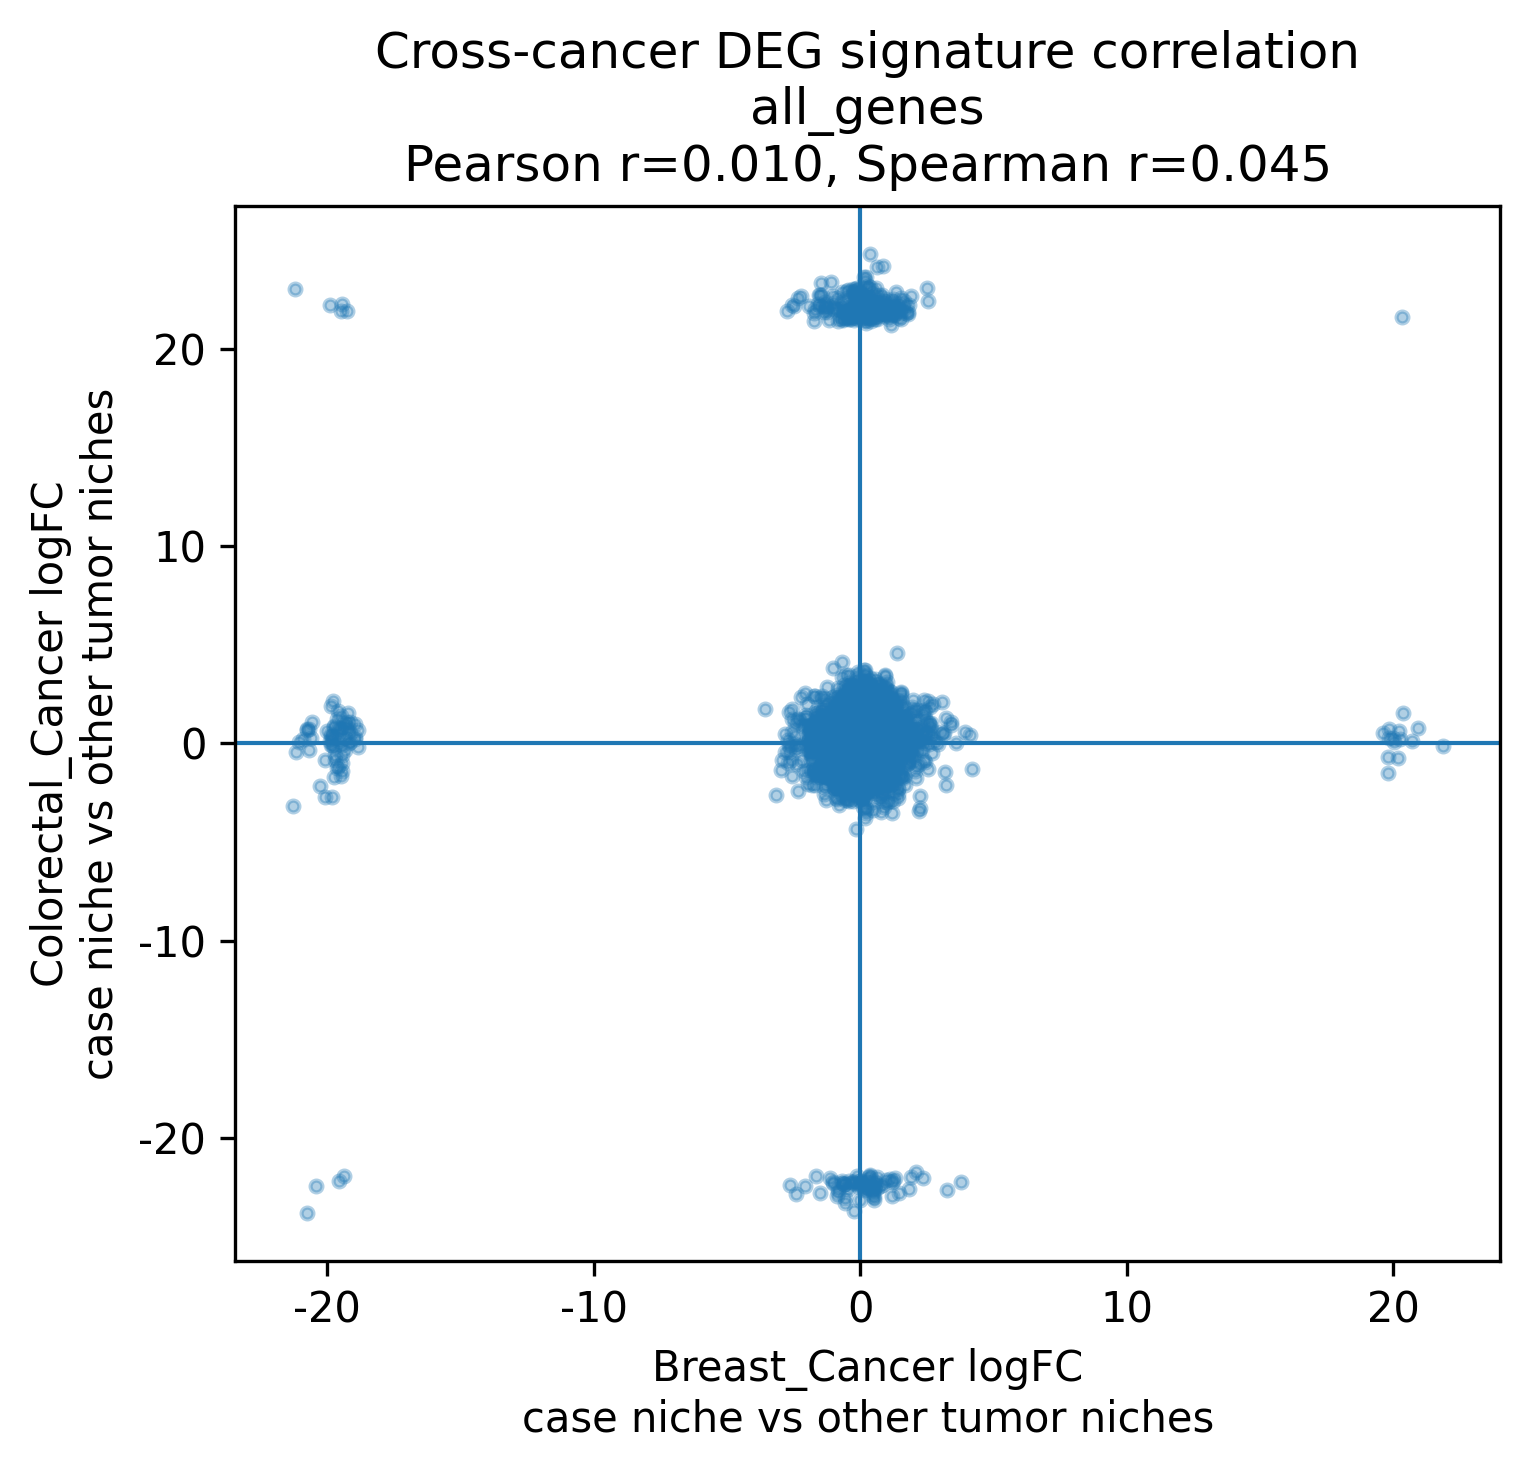

GSEA merged saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/all_genes/GSEA_cross_cancer_merged_all_genes.csv
GSEA heatmap saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/all_genes/GSEA_NES_heatmap_all_genes.png
GSEA heatmap saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/all_genes/GSEA_NES_heatmap_all_genes.pdf


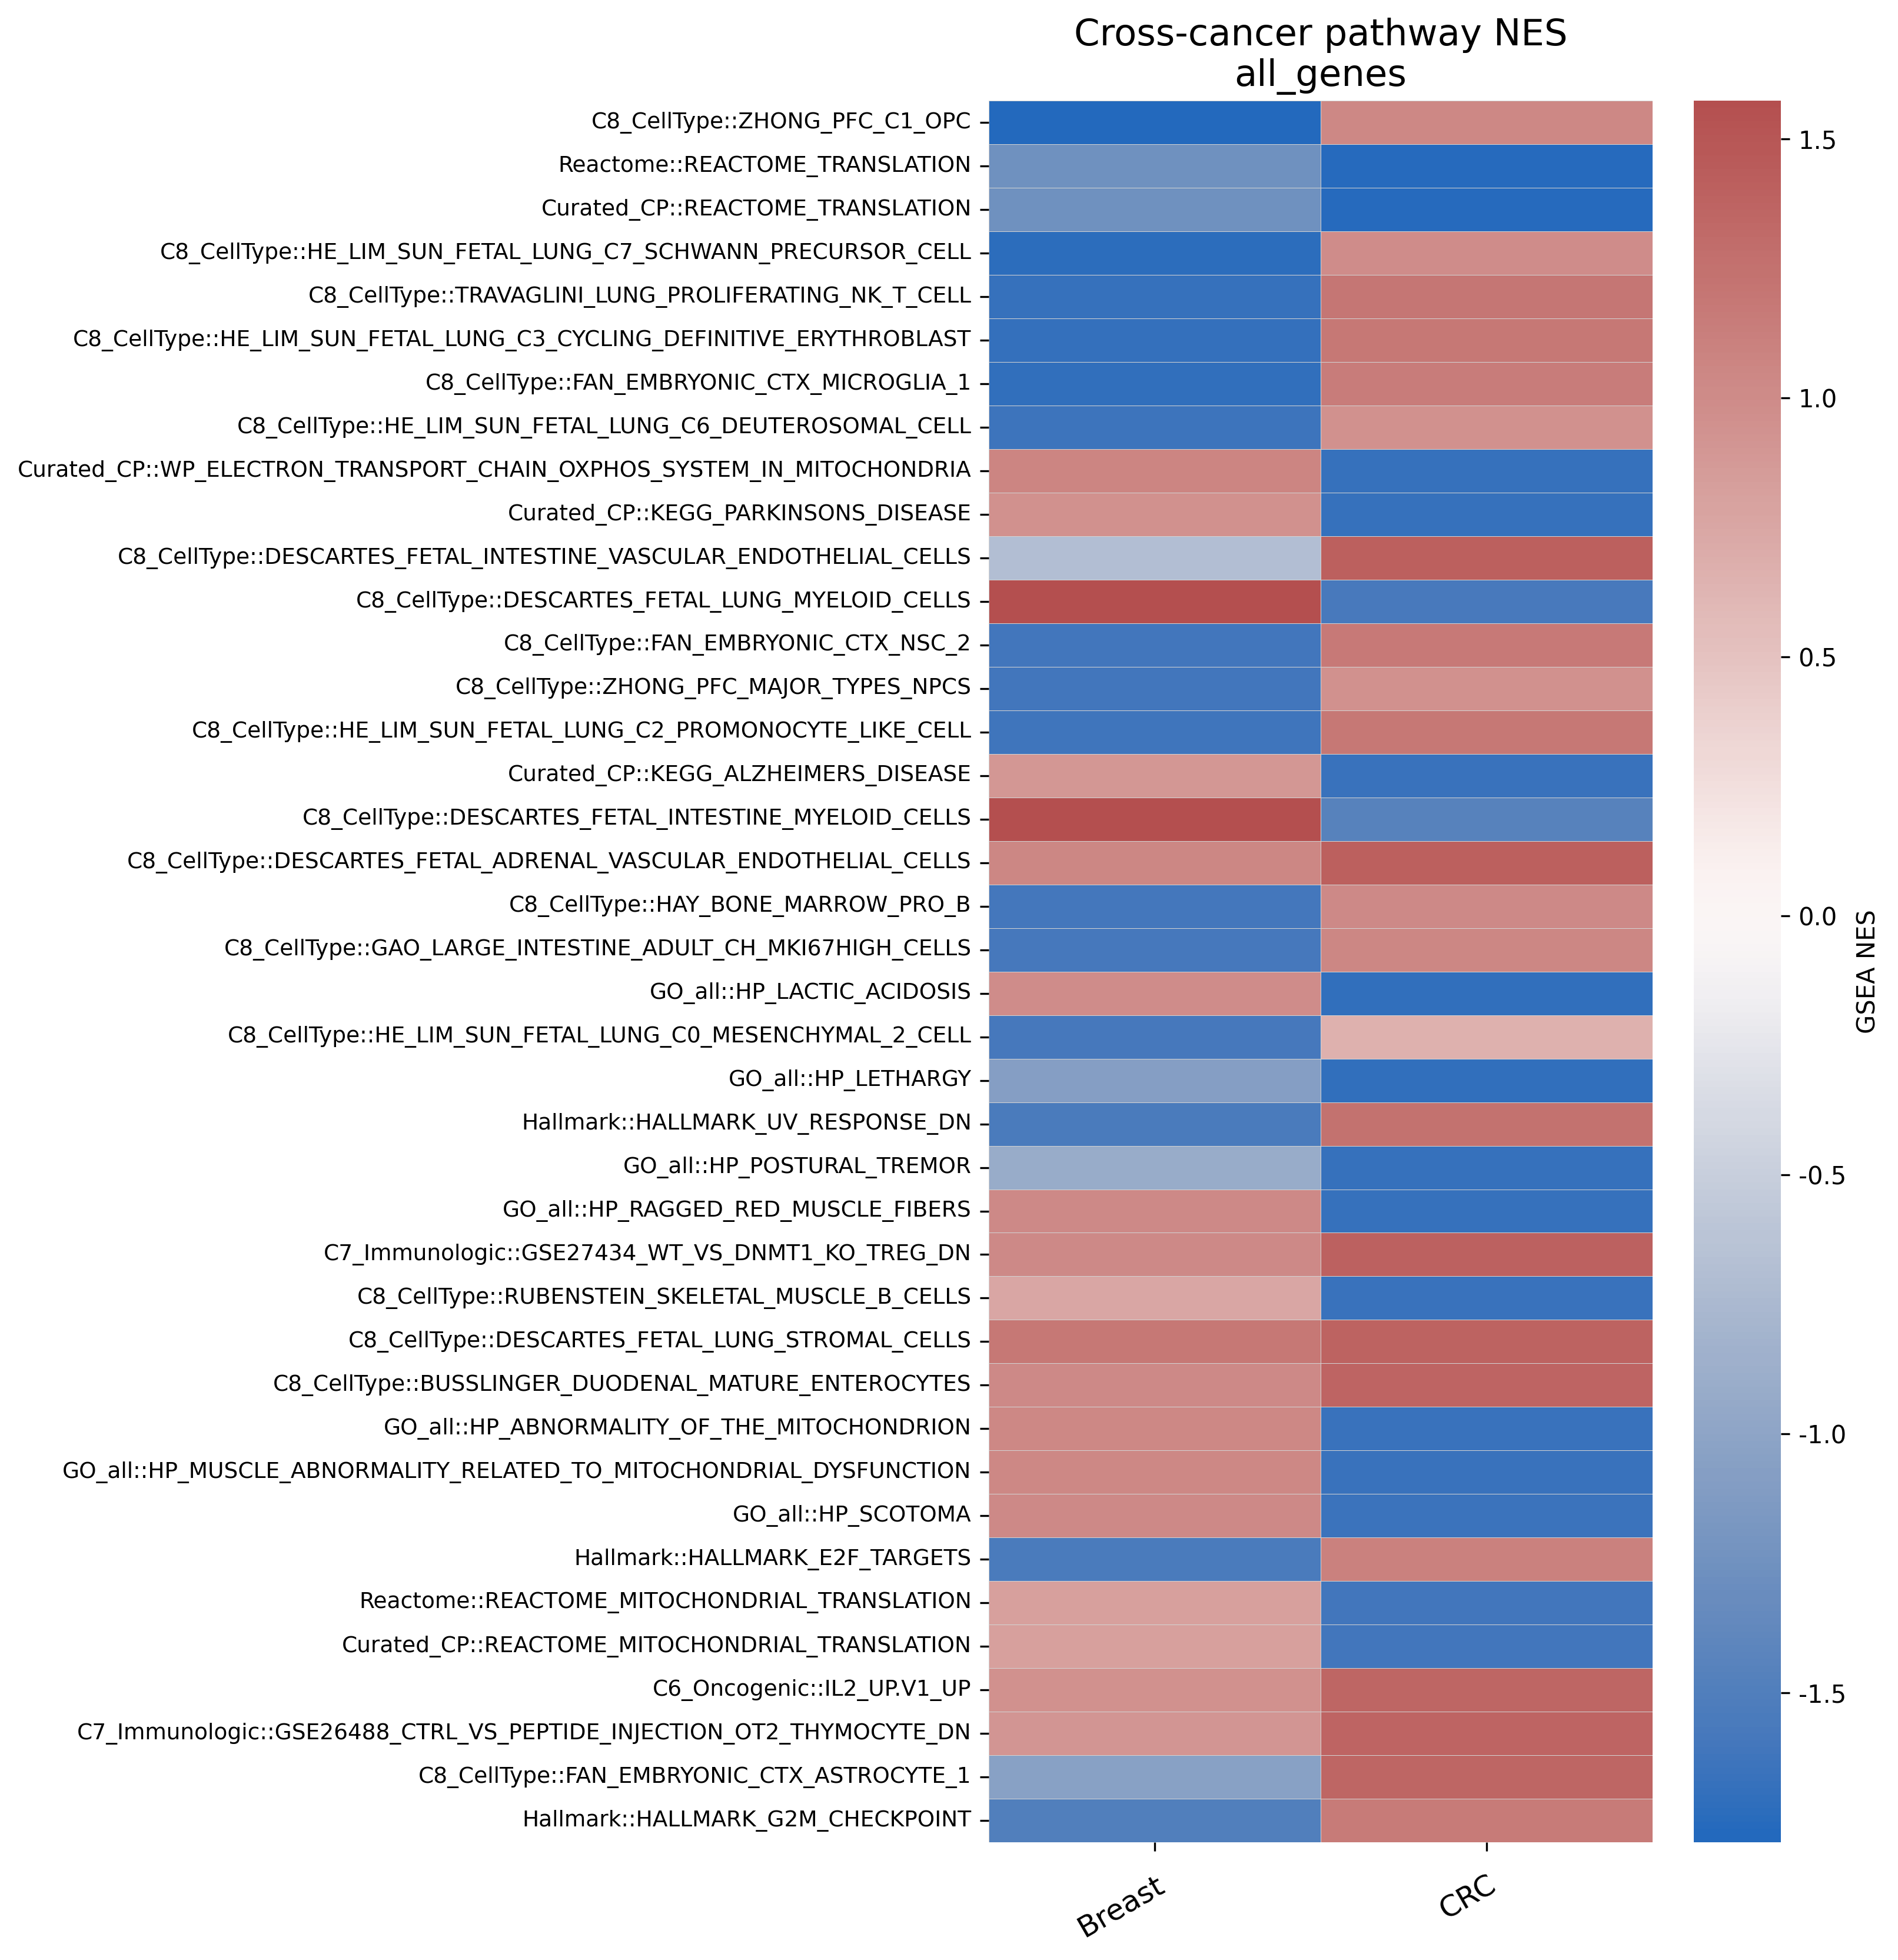

GSEA category summary saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/all_genes/GSEA_cross_cancer_category_summary_all_genes.csv

跨癌种比较 variant: TMCN_genes_excluded


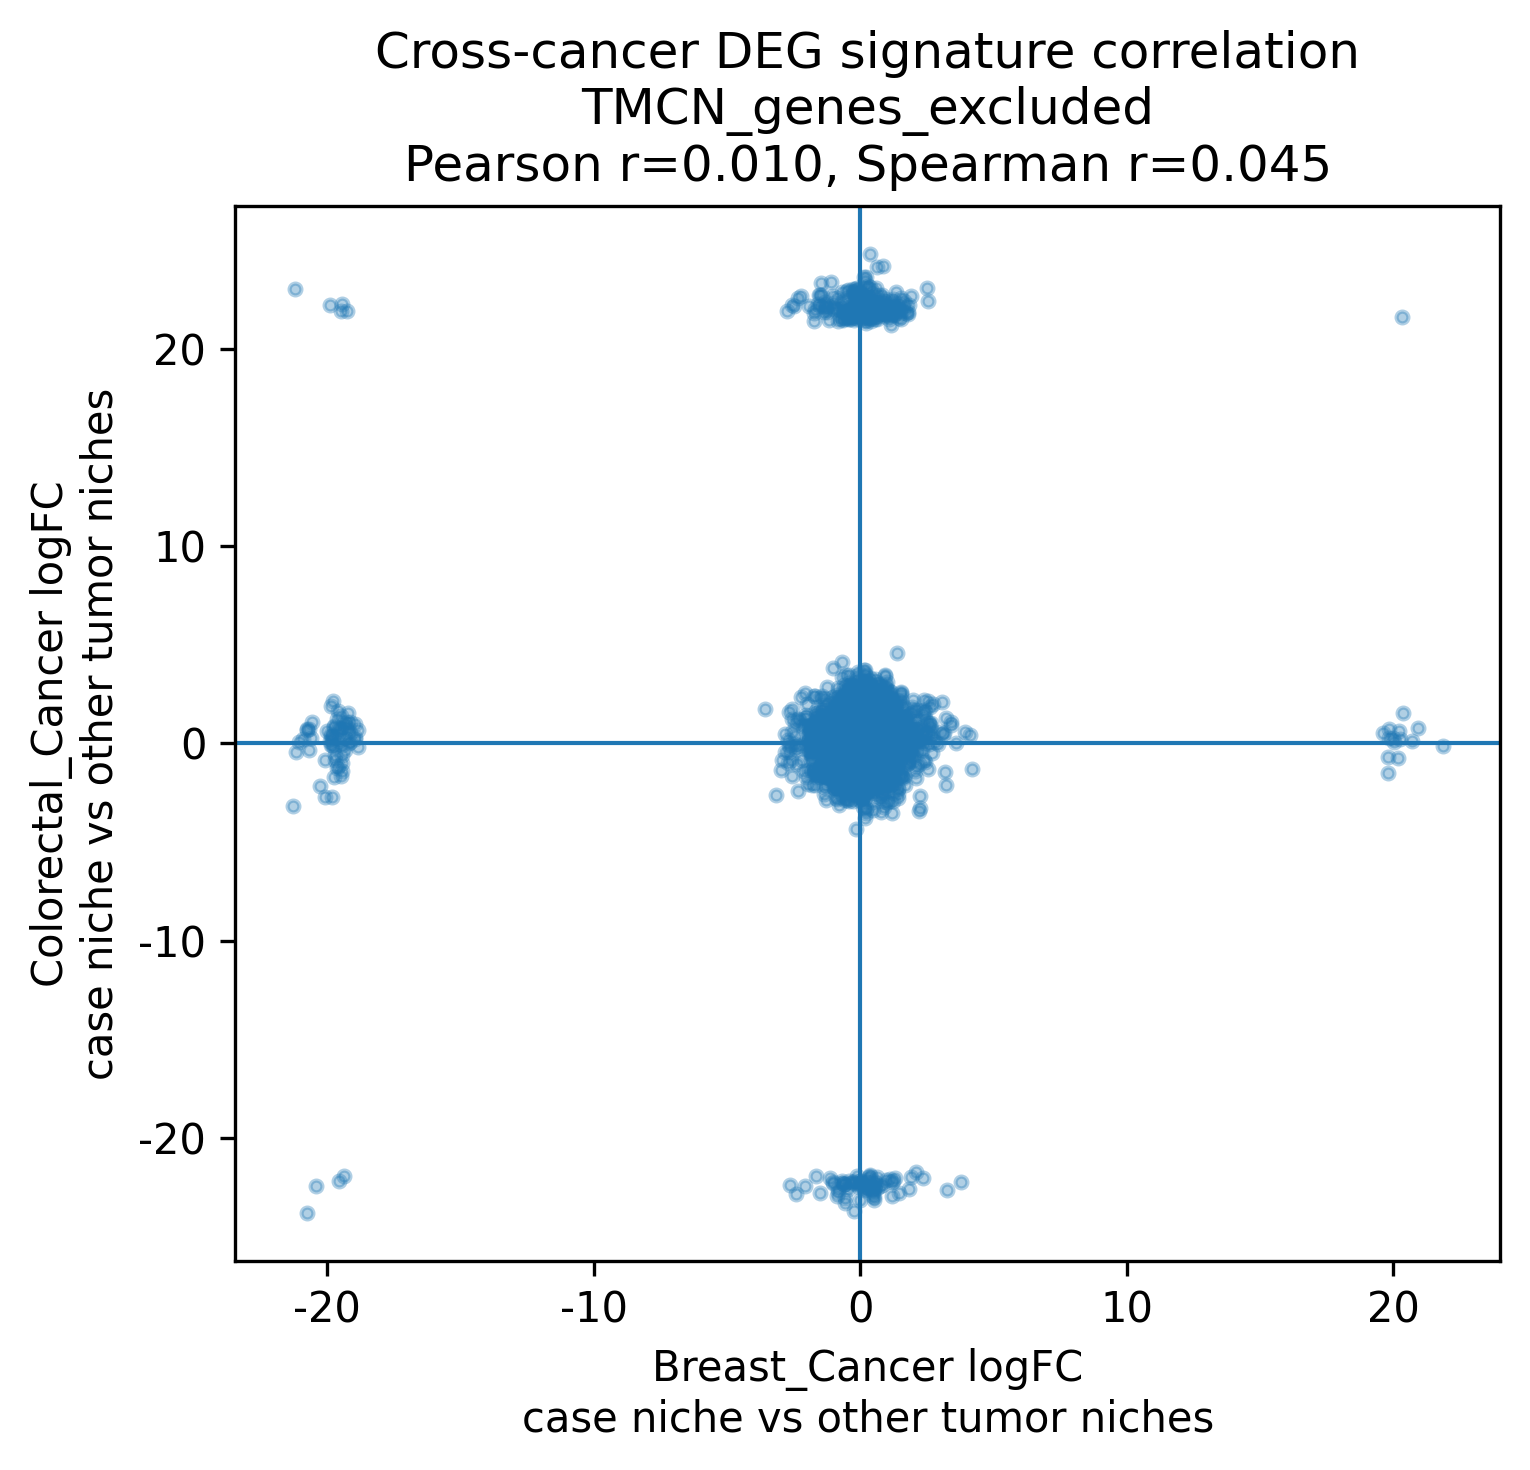

GSEA merged saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/TMCN_genes_excluded/GSEA_cross_cancer_merged_TMCN_genes_excluded.csv
GSEA heatmap saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/TMCN_genes_excluded/GSEA_NES_heatmap_TMCN_genes_excluded.png
GSEA heatmap saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/TMCN_genes_excluded/GSEA_NES_heatmap_TMCN_genes_excluded.pdf


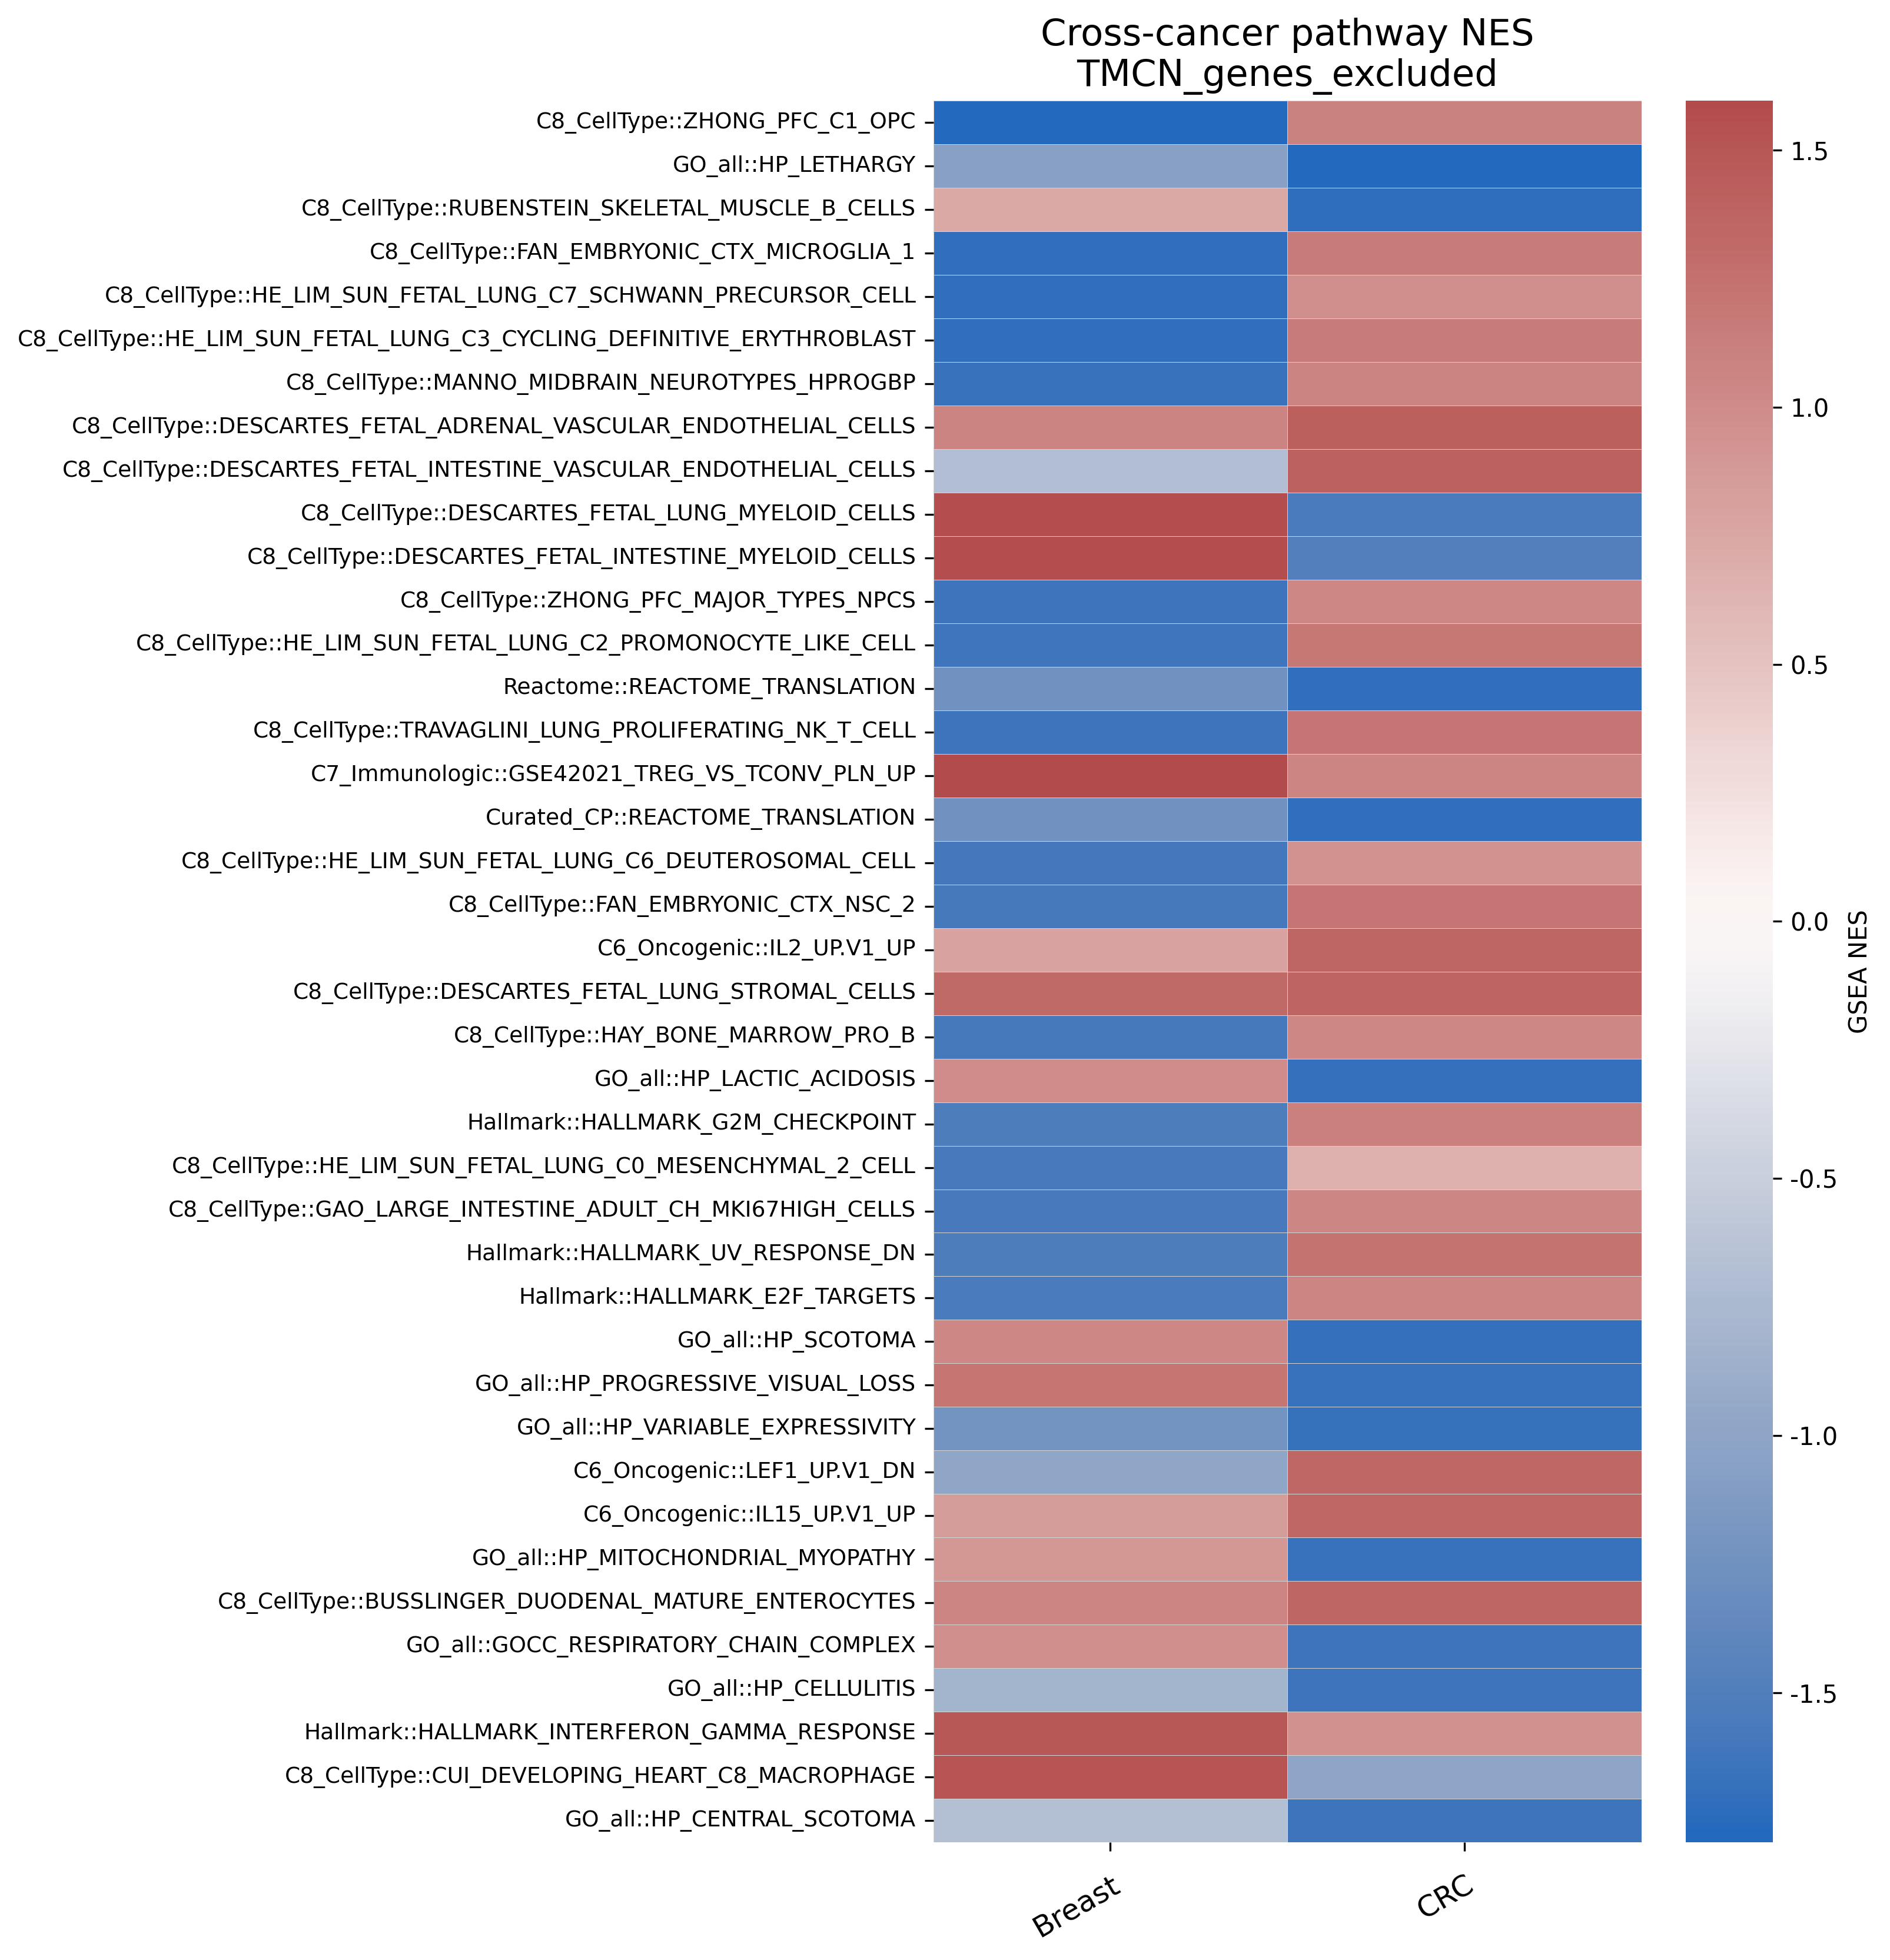

GSEA category summary saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/TMCN_genes_excluded/GSEA_cross_cancer_category_summary_TMCN_genes_excluded.csv

跨癌种比较 variant: current_axis_genes_excluded


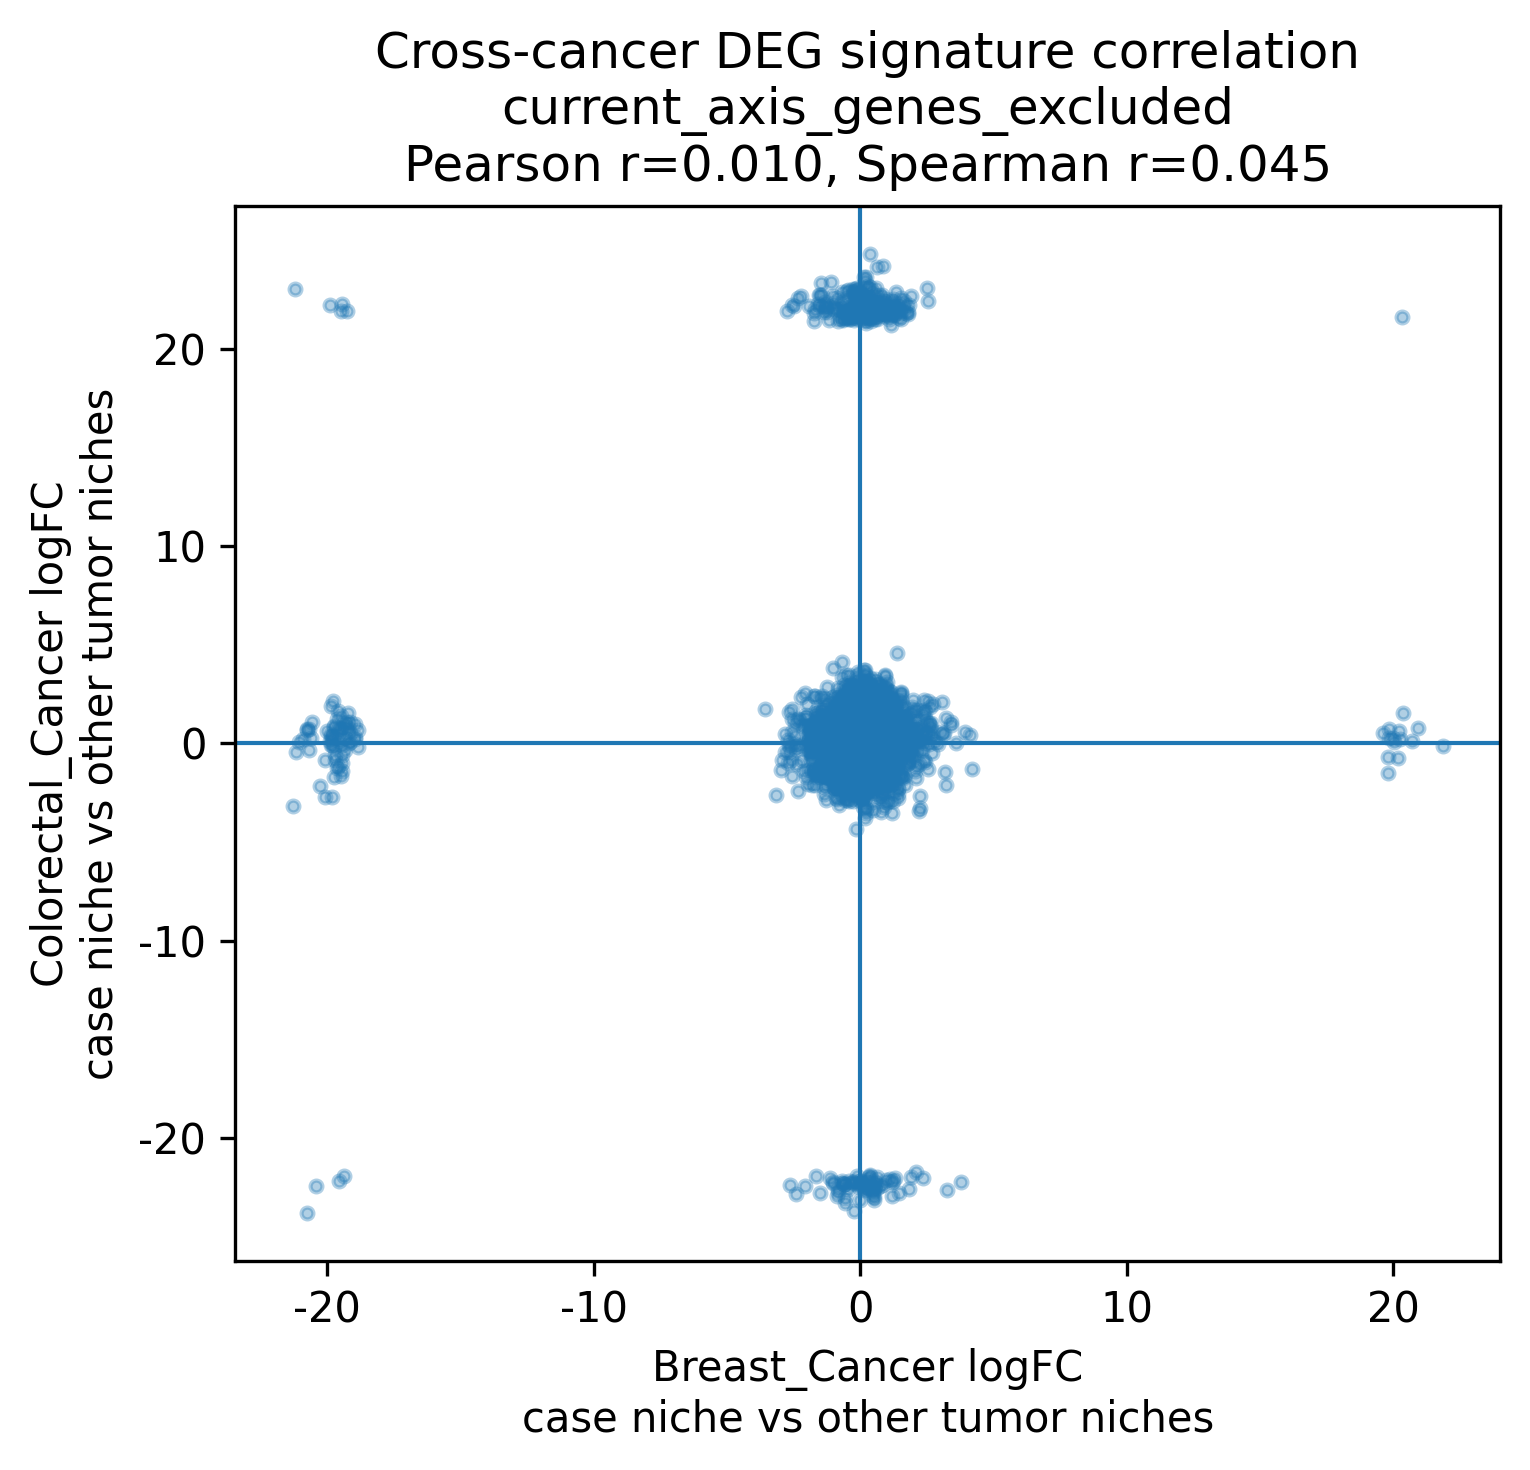

GSEA merged saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/current_axis_genes_excluded/GSEA_cross_cancer_merged_current_axis_genes_excluded.csv
GSEA heatmap saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/current_axis_genes_excluded/GSEA_NES_heatmap_current_axis_genes_excluded.png
GSEA heatmap saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/current_axis_genes_excluded/GSEA_NES_heatmap_current_axis_genes_excluded.pdf


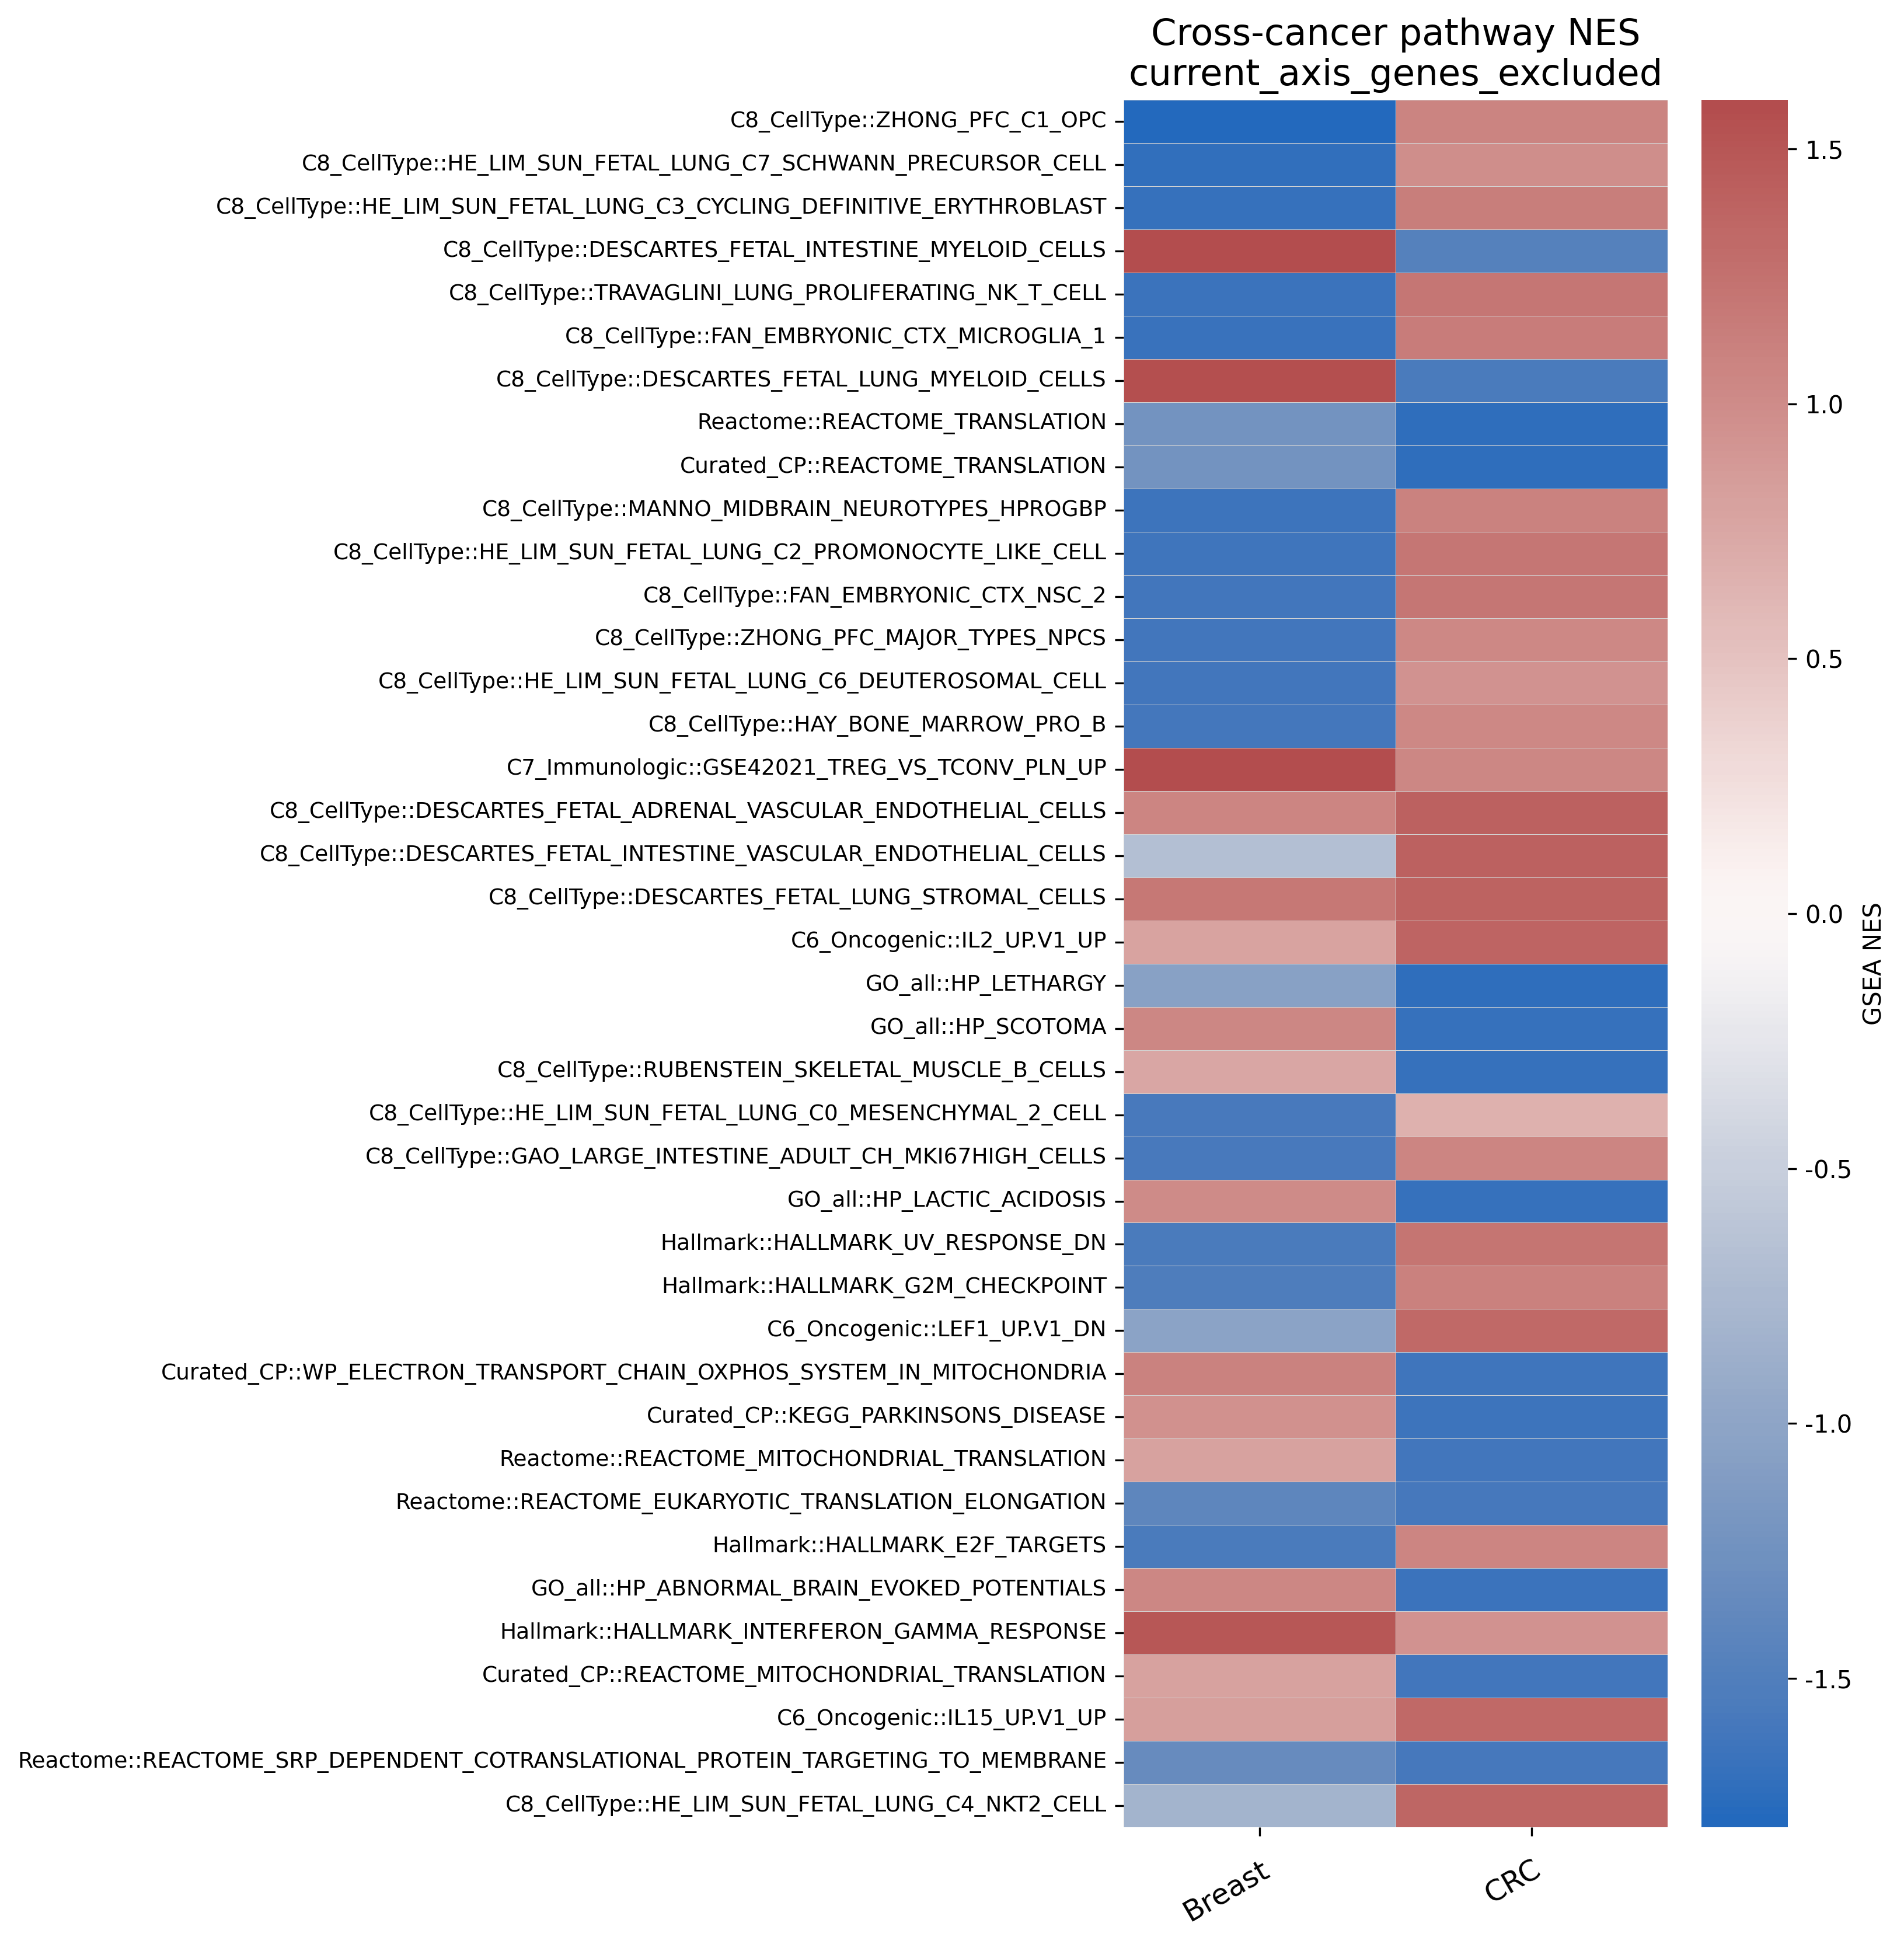

GSEA category summary saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/current_axis_genes_excluded/GSEA_cross_cancer_category_summary_current_axis_genes_excluded.csv

✅ DEG compare summary:


,variant,n_shared_genes,pearson_logFC_r,pearson_logFC_p,spearman_logFC_r,spearman_logFC_p,conserved_up,conserved_down,opposite_direction,Breast_Cancer_specific_up,Colorectal_Cancer_specific_up
0,all_genes,17431,0.010044,0.184821,0.045080,2.609958e-09,282,20,242,1286,1582
1,TMCN_genes_excluded,17385,0.010031,0.185965,0.045159,2.569270e-09,279,20,240,1281,1577
2,current_axis_genes_excluded,17409,0.010064,0.184261,0.045364,2.122630e-09,279,20,240,1283,1579



✅ GSEA category summary:


,pathway_category,n_pathways,analysis_variant
0,not_significant_or_weak,20373,all_genes
1,Colorectal_Cancer_specific_down_pathway,198,all_genes
2,Colorectal_Cancer_specific_up_pathway,133,all_genes
3,Breast_Cancer_specific_down_pathway,45,all_genes
4,Breast_Cancer_specific_up_pathway,30,all_genes
5,opposite_direction_pathway,5,all_genes
6,conserved_down_pathway,1,all_genes
7,not_significant_or_weak,20283,TMCN_genes_excluded
8,Colorectal_Cancer_specific_down_pathway,219,TMCN_genes_excluded
9,Colorectal_Cancer_specific_up_pathway,124,TMCN_genes_excluded


In [6]:

# =========================================================
# Cell 5: 两个癌种之间的 DEG/GSEA 签名比较
# =========================================================

dataset_names = list(DATASETS.keys())
if len(dataset_names) != 2:
    raise ValueError("这个 notebook 设计为两个癌种之间比较。")

all_deg_compare_summaries = []
all_gsea_category_summaries = []

for variant_name in ANALYSIS_VARIANTS:
    print("\n" + "=" * 100)
    print(f"跨癌种比较 variant: {variant_name}")
    print("=" * 100)

    if dataset_names[0] not in deg_tables[variant_name] or dataset_names[1] not in deg_tables[variant_name]:
        print(f"⚠️ {variant_name}: DEG 表不完整，跳过。")
        continue

    variant_compare_dir = ensure_dir(COMPARE_DIR / variant_name)

    merged_deg, deg_compare_summary = compare_two_deg_tables(
        deg_a=deg_tables[variant_name][dataset_names[0]],
        deg_b=deg_tables[variant_name][dataset_names[1]],
        name_a=dataset_names[0],
        name_b=dataset_names[1],
        outdir=variant_compare_dir,
        variant_name=variant_name,
        fdr_cutoff=DEG_FDR_CUTOFF,
        logfc_cutoff=DEG_LOGFC_CUTOFF
    )
    if len(deg_compare_summary) > 0:
        all_deg_compare_summaries.append(deg_compare_summary)

    if len(merged_deg) > 0 and "signature_category" in merged_deg.columns:
        for cat, sub in merged_deg.groupby("signature_category"):
            sub = sub.sort_values(
                [f"pvals_adj_{dataset_names[0]}", f"pvals_adj_{dataset_names[1]}"],
                ascending=[True, True]
            )
            sub.to_csv(variant_compare_dir / f"DEG_genes_{safe_filename(cat)}_{variant_name}.csv", index=False)

    gsea_merged, gsea_summary = compare_gsea_results(
        gsea_dict=gsea_tables[variant_name],
        dataset_names=dataset_names,
        outdir=variant_compare_dir,
        variant_name=variant_name,
        fdr_cutoff=GSEA_FDR_CUTOFF,
        top_n_terms=GSEA_TOP_N_TERMS
    )
    if len(gsea_summary) > 0:
        gsea_summary["analysis_variant"] = variant_name
        all_gsea_category_summaries.append(gsea_summary)

if len(all_deg_compare_summaries) > 0:
    deg_compare_summary_df = pd.DataFrame(all_deg_compare_summaries)
    deg_compare_summary_df.to_csv(SUMMARY_DIR / f"cross_cancer_DEG_compare_summary_{safe_filename(TARGET_NICHE)}.csv", index=False)
    print("\n✅ DEG compare summary:")
    display(deg_compare_summary_df)

if len(all_gsea_category_summaries) > 0:
    gsea_category_summary_df = pd.concat(all_gsea_category_summaries, ignore_index=True)
    gsea_category_summary_df.to_csv(SUMMARY_DIR / f"cross_cancer_GSEA_category_summary_{safe_filename(TARGET_NICHE)}.csv", index=False)
    print("\n✅ GSEA category summary:")
    display(gsea_category_summary_df)


In [7]:

# =========================================================
# Cell 6: 快速查看主结果
# =========================================================

MAIN_VARIANT = "TMCN_genes_excluded"

print("主结果建议优先查看:", MAIN_VARIANT)

main_compare_dir = COMPARE_DIR / MAIN_VARIANT

files_to_check = [
    SUMMARY_DIR / f"DEG_summary_{safe_filename(TARGET_NICHE)}.csv",
    SUMMARY_DIR / f"cross_cancer_DEG_compare_summary_{safe_filename(TARGET_NICHE)}.csv",
    SUMMARY_DIR / f"cross_cancer_GSEA_category_summary_{safe_filename(TARGET_NICHE)}.csv",
    main_compare_dir / f"DEG_cross_cancer_merged_{MAIN_VARIANT}.csv",
    main_compare_dir / f"GSEA_cross_cancer_merged_{MAIN_VARIANT}.csv",
    main_compare_dir / f"DEG_logFC_scatter_{MAIN_VARIANT}.png",
    main_compare_dir / f"GSEA_NES_heatmap_{MAIN_VARIANT}.png",
]

for p in files_to_check:
    print("✅" if Path(p).exists() else "⚠️", p)

gsea_merged_path = main_compare_dir / f"GSEA_cross_cancer_merged_{MAIN_VARIANT}.csv"
if gsea_merged_path.exists():
    gsea_merged = pd.read_csv(gsea_merged_path)
    print("\nPathway categories:")
    display(gsea_merged["pathway_category"].value_counts().rename_axis("category").reset_index(name="n"))

    show_cols = [c for c in gsea_merged.columns if c in [
        "collection", "Term", "pathway_category",
        f"NES_{list(DATASETS.keys())[0]}", f"FDR_{list(DATASETS.keys())[0]}",
        f"NES_{list(DATASETS.keys())[1]}", f"FDR_{list(DATASETS.keys())[1]}",
    ]]
    display(gsea_merged[show_cols].head(30))

deg_merged_path = main_compare_dir / f"DEG_cross_cancer_merged_{MAIN_VARIANT}.csv"
if deg_merged_path.exists():
    deg_merged = pd.read_csv(deg_merged_path)
    print("\nDEG signature categories:")
    display(deg_merged["signature_category"].value_counts().rename_axis("category").reset_index(name="n"))
    display(deg_merged.head(30))


主结果建议优先查看: TMCN_genes_excluded
✅ /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/summary_tables/DEG_summary_Multi_Axis_Lactate_Glutamine.csv
✅ /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/summary_tables/cross_cancer_DEG_compare_summary_Multi_Axis_Lactate_Glutamine.csv
✅ /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/summary_tables/cross_cancer_GSEA_category_summary_Multi_Axis_Lactate_Glutamine.csv
✅ /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/TMCN_genes_excluded/DEG_cross_cancer_merged_TMCN_genes_excluded.csv
✅ /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/TMCN_genes_excluded/GSEA_cross_can

,category,n
0,not_significant_or_weak,20283
1,Colorectal_Cancer_specific_down_pathway,219
2,Colorectal_Cancer_specific_up_pathway,124
3,Breast_Cancer_specific_down_pathway,47
4,Breast_Cancer_specific_up_pathway,37
5,opposite_direction_pathway,6
6,conserved_down_pathway,1


,collection,Term,NES_Breast_Cancer,FDR_Breast_Cancer,NES_Colorectal_Cancer,FDR_Colorectal_Cancer,pathway_category
0,C8_CellType,ZHONG_PFC_C1_OPC,-1.791320,0.000000,1.099795,0.736203,Breast_Cancer_specific_down_pathway
1,GO_all,HP_LETHARGY,-1.067596,0.963841,-1.778747,0.000000,Colorectal_Cancer_specific_down_pathway
2,C8_CellType,RUBENSTEIN_SKELETAL_MUSCLE_B_CELLS,0.742429,0.957295,-1.721125,0.000000,Colorectal_Cancer_specific_down_pathway
3,C8_CellType,FAN_EMBRYONIC_CTX_MICROGLIA_1,-1.705077,0.000000,1.157904,0.514140,Breast_Cancer_specific_down_pathway
4,C8_CellType,HE_LIM_SUN_FETAL_LUNG_C7_SCHWANN_PRECURSOR_CELL,-1.702334,0.000000,0.966727,1.000000,Breast_Cancer_specific_down_pathway
5,C8_CellType,HE_LIM_SUN_FETAL_LUNG_C3_CYCLING_DEFINITIVE_ER...,-1.698725,0.000000,1.154358,0.534811,Breast_Cancer_specific_down_pathway
6,C8_CellType,MANNO_MIDBRAIN_NEUROTYPES_HPROGBP,-1.666787,0.000230,1.087607,0.799815,Breast_Cancer_specific_down_pathway
7,C8_CellType,DESCARTES_FETAL_ADRENAL_VASCULAR_ENDOTHELIAL_C...,1.081125,0.851157,1.413944,0.000869,Colorectal_Cancer_specific_up_pathway
8,C8_CellType,DESCARTES_FETAL_INTESTINE_VASCULAR_ENDOTHELIAL...,-0.692340,0.996103,1.407864,0.001303,Colorectal_Cancer_specific_up_pathway
9,C8_CellType,DESCARTES_FETAL_LUNG_MYELOID_CELLS,1.572883,0.001369,-1.559524,0.102877,opposite_direction_pathway



DEG signature categories:


,category,n
0,not_significant_or_weak,12913
1,Colorectal_Cancer_specific_up,1577
2,Breast_Cancer_specific_up,1281
3,Breast_Cancer_specific_down,949
4,conserved_up,279
5,opposite_direction,240
6,Colorectal_Cancer_specific_down,126
7,conserved_down,20


,gene,logfoldchanges_Breast_Cancer,pvals_adj_Breast_Cancer,scores_Breast_Cancer,logfoldchanges_Colorectal_Cancer,pvals_adj_Colorectal_Cancer,scores_Colorectal_Cancer,signature_category
0,CPB1,1.933087,2.201716e-113,22.970856,0.875311,9.973203e-01,0.135331,Breast_Cancer_specific_up
1,S100G,1.475435,3.891456e-111,22.728758,-1.475654,9.973203e-01,-0.061802,Breast_Cancer_specific_up
2,ABHD2,1.148497,3.115295e-133,24.921963,-0.008922,9.973203e-01,-0.273454,Breast_Cancer_specific_up
3,KLHDC7B,1.551486,4.453910e-95,21.004670,-0.295991,9.973203e-01,-0.047654,Breast_Cancer_specific_up
4,CSTA,1.190519,1.160275e-110,22.677473,-1.162017,9.973203e-01,-0.446015,Breast_Cancer_specific_up
5,ERLIN2,0.982770,3.989891e-122,23.846468,0.496660,1.267146e-02,3.271766,conserved_up
6,SCUBE3,1.739969,4.235244e-67,17.628777,0.609236,9.973203e-01,0.208488,Breast_Cancer_specific_up
7,SHISA2,-1.445828,3.735677e-74,-18.546103,0.320418,9.973203e-01,0.206254,Breast_Cancer_specific_down
8,ADIRF,0.679537,1.550578e-155,26.941700,0.753683,1.809521e-14,8.310465,conserved_up
9,CTPS2,1.016614,6.987972e-102,21.746860,0.616686,1.457102e-03,3.979135,conserved_up



## 结果解读建议

优先查看目录：

```text
/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/TMCN_genes_excluded/
```

重点文件：

```text
DEG_cross_cancer_merged_TMCN_genes_excluded.csv
GSEA_cross_cancer_merged_TMCN_genes_excluded.csv
DEG_logFC_scatter_TMCN_genes_excluded.png
GSEA_NES_heatmap_TMCN_genes_excluded.png
```

解读逻辑：

- `conserved_up` / `conserved_up_pathway`：两个癌种中该生态位共同增强的基因或通路。
- `Cancer_specific_up`：某个癌种中该生态位特异增强的基因或通路。
- `opposite_direction`：两个癌种方向相反，提示同名生态位存在癌种特异性功能重塑。



生成最终版图片: all_genes


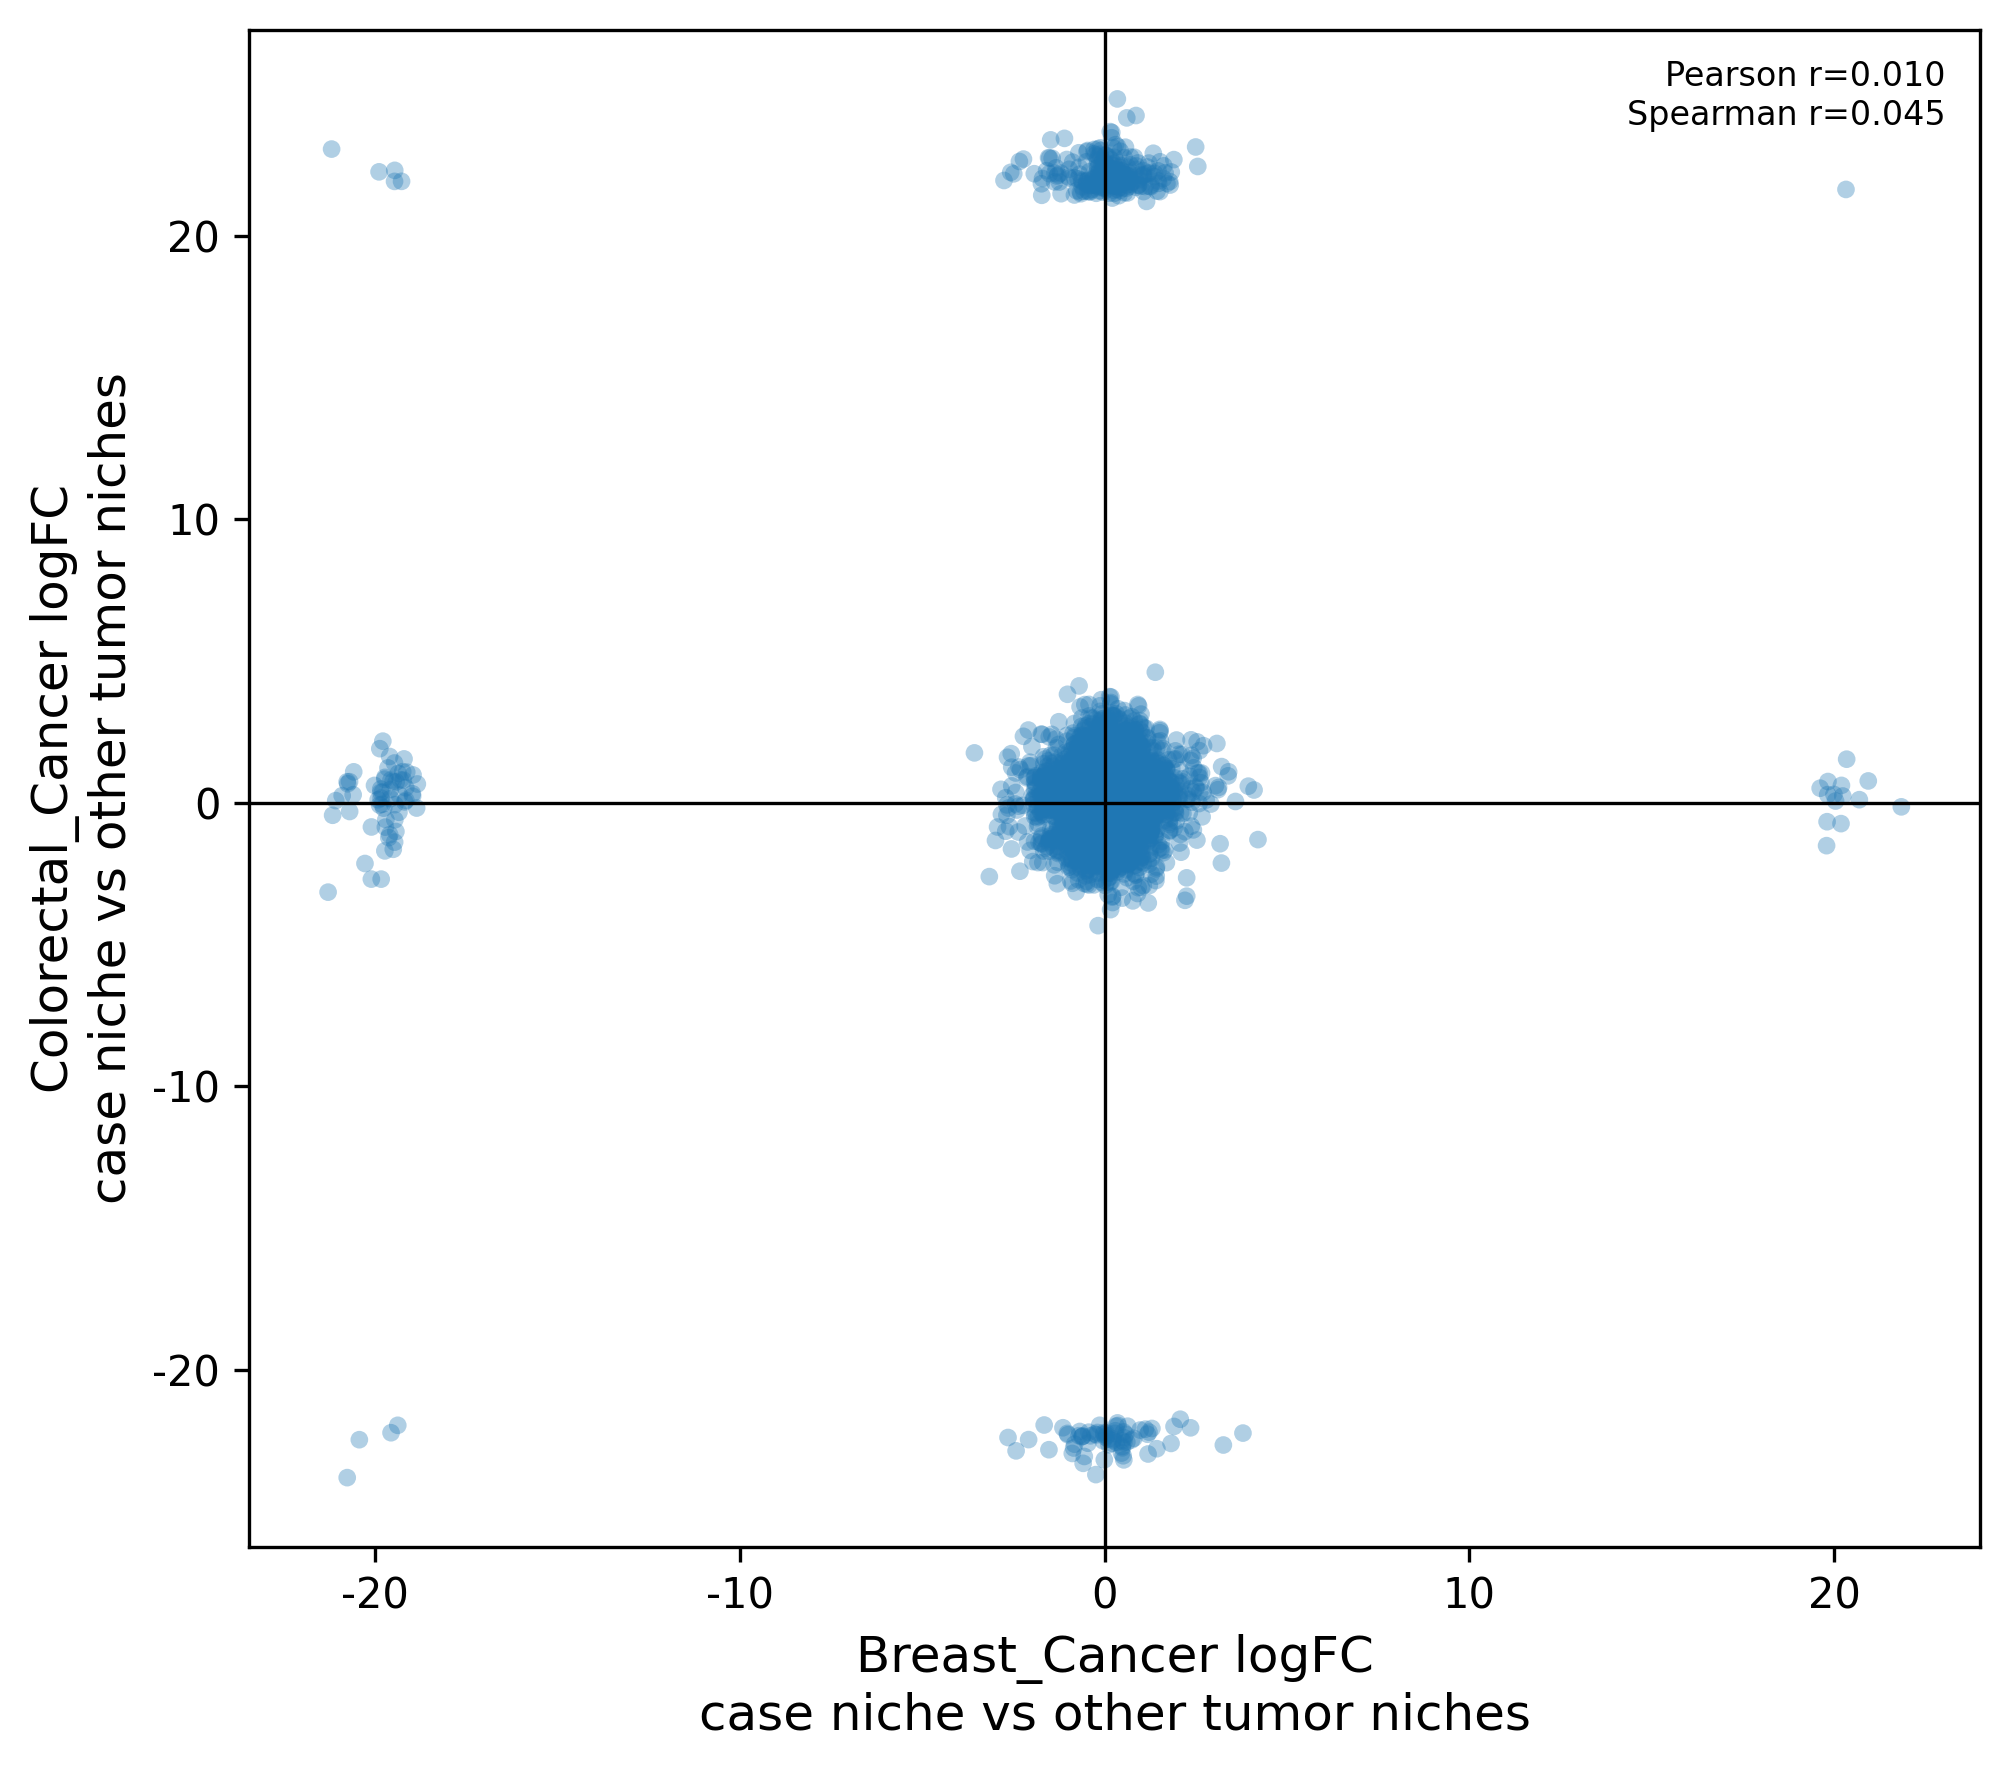

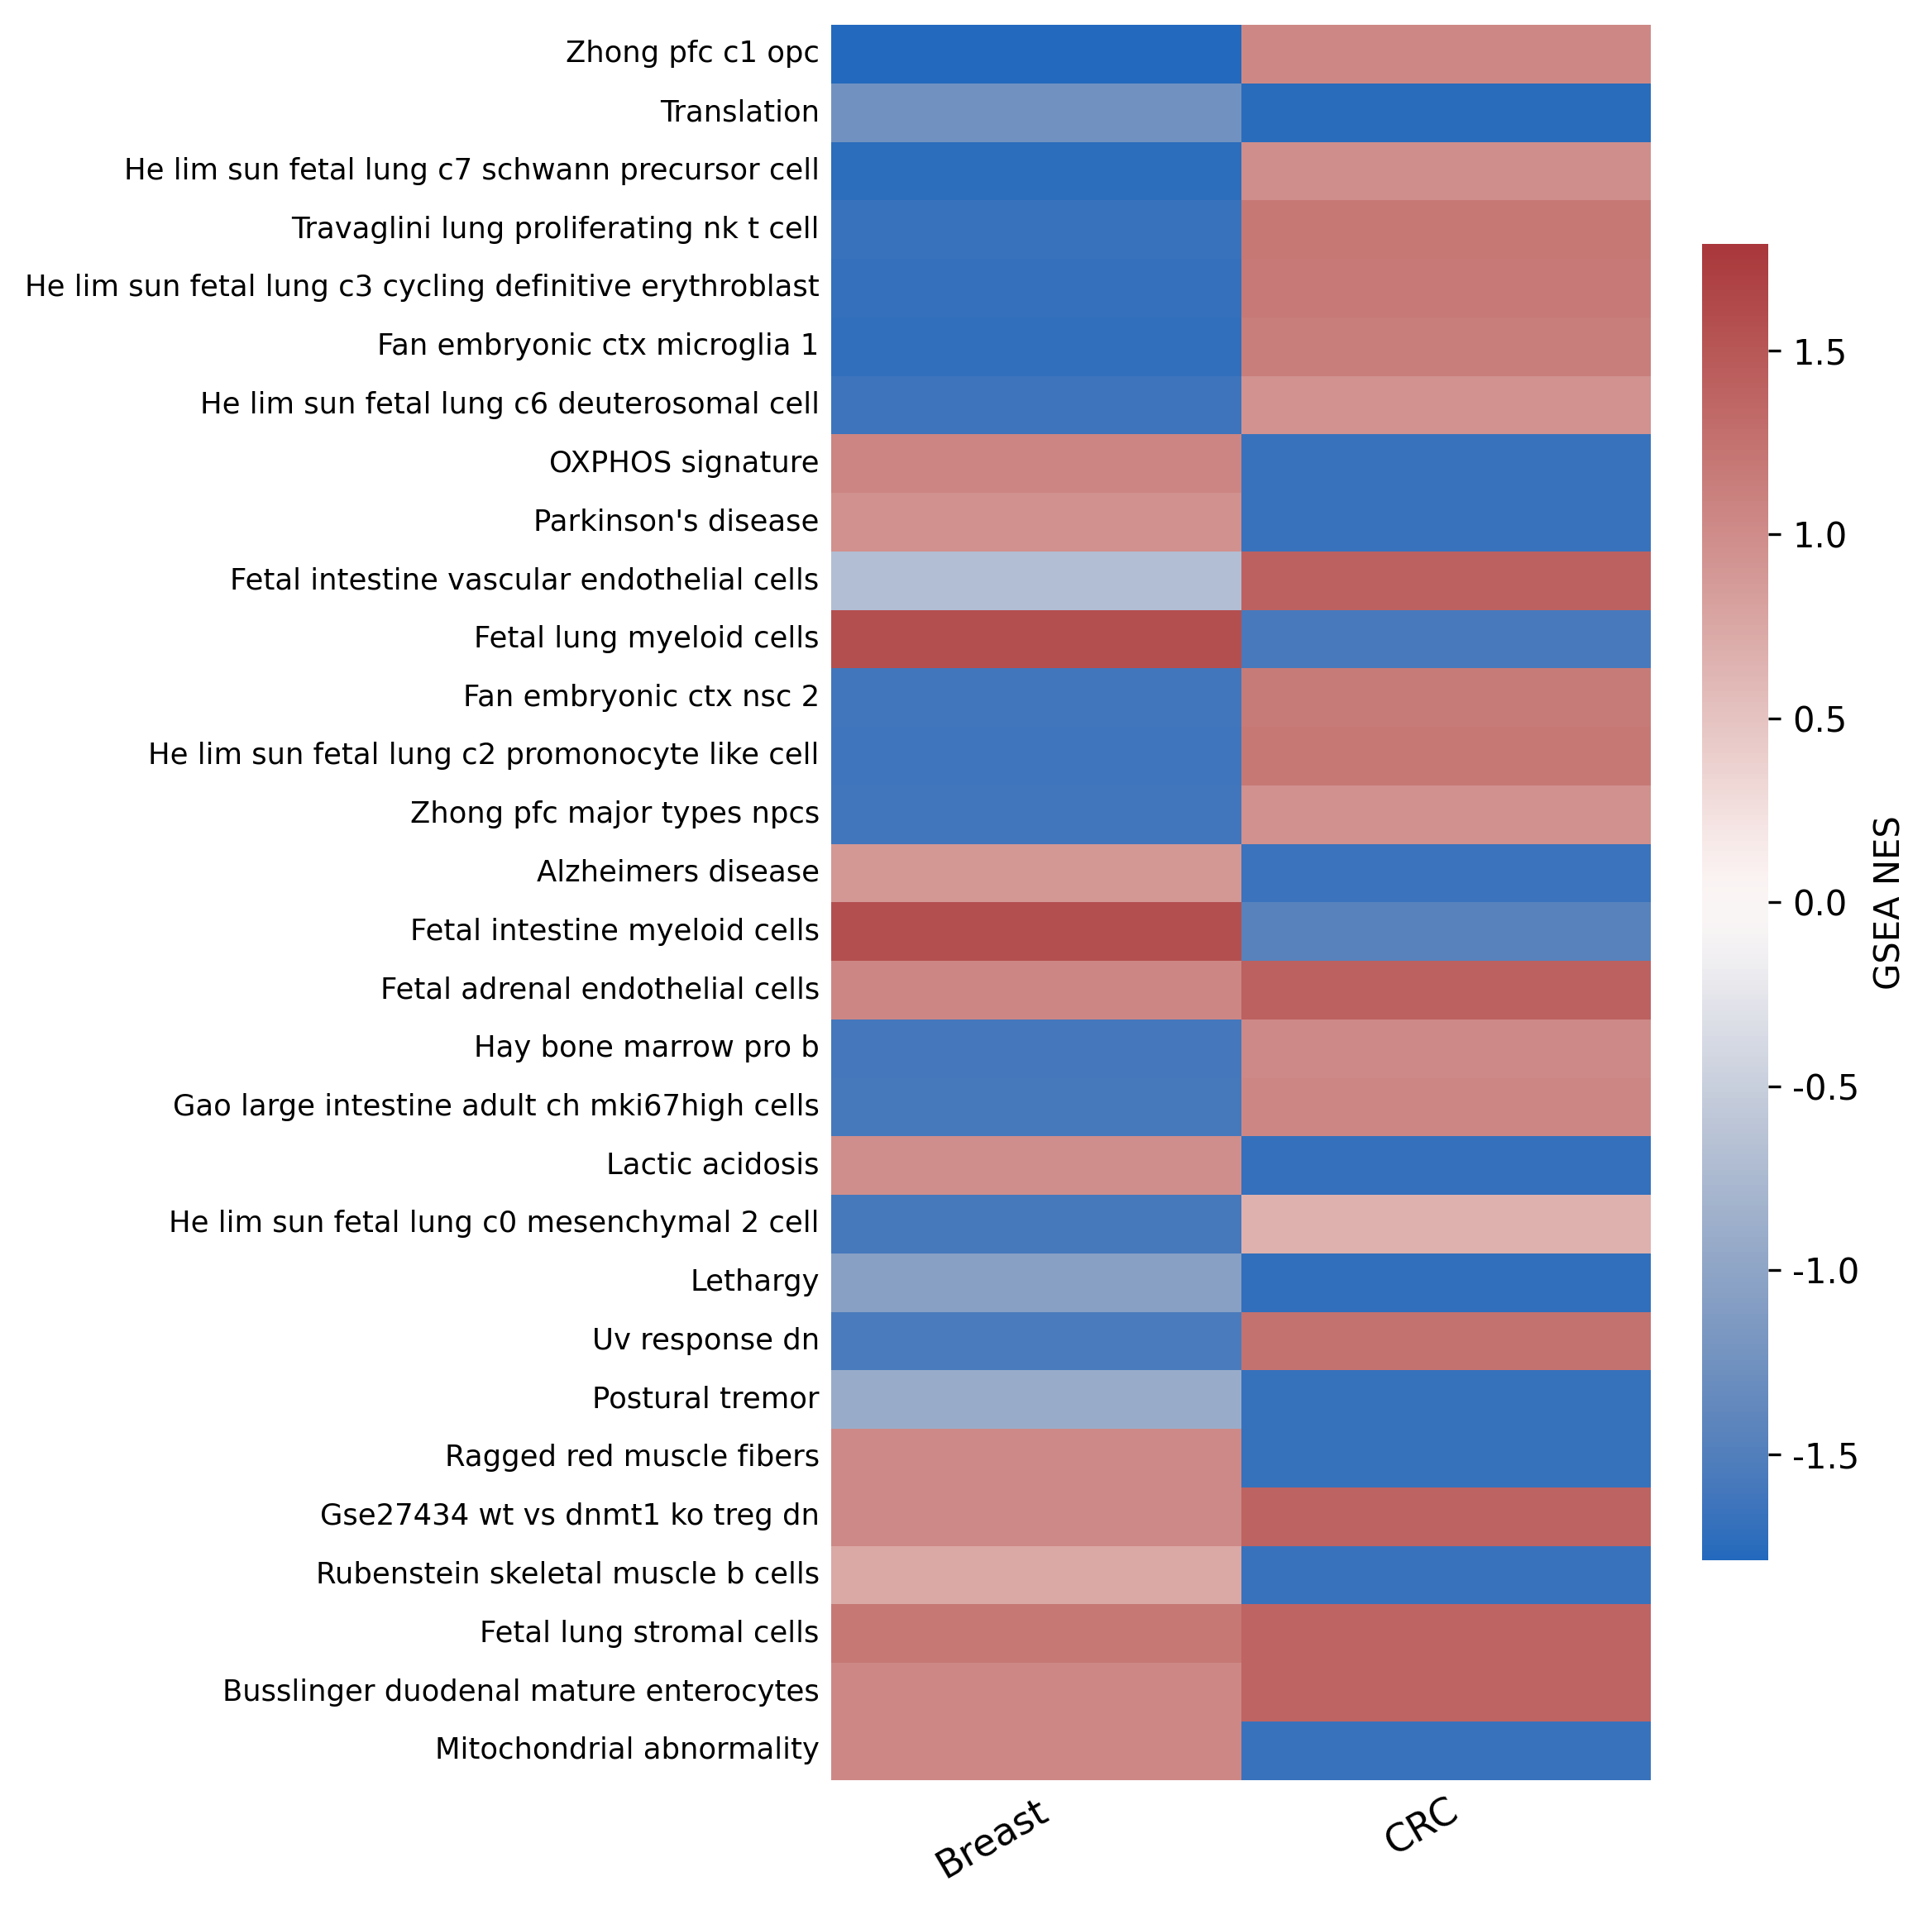


生成最终版图片: TMCN_genes_excluded


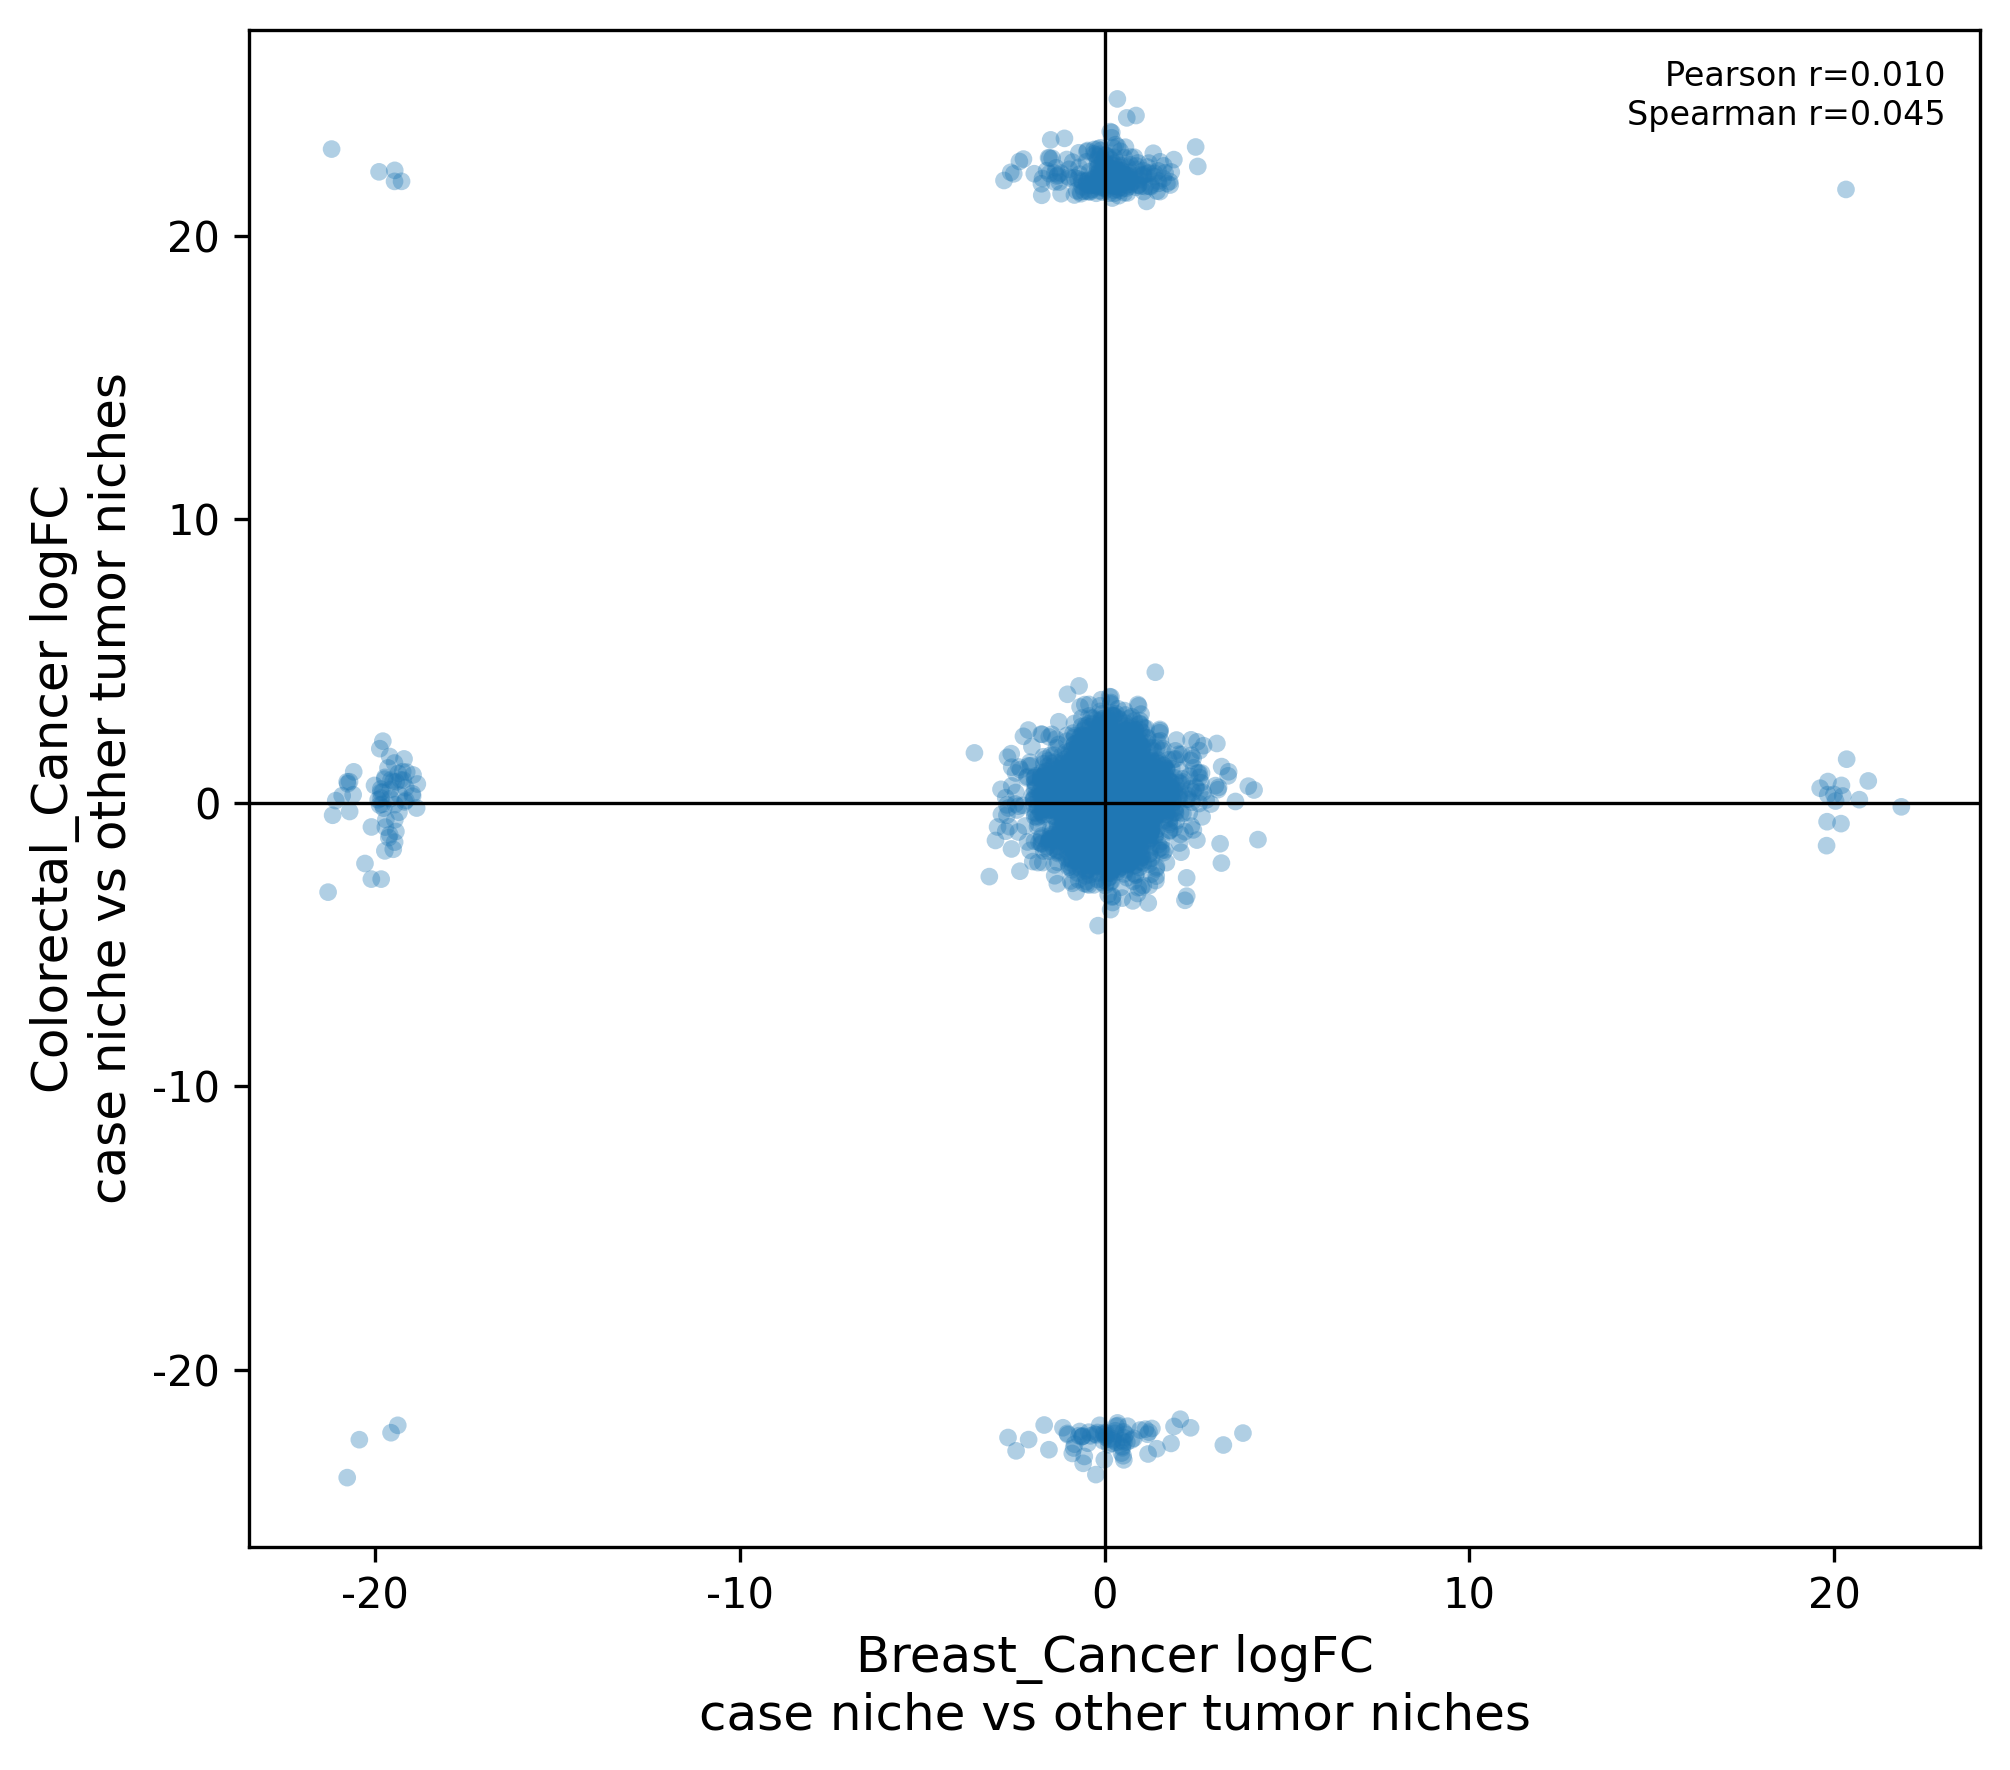

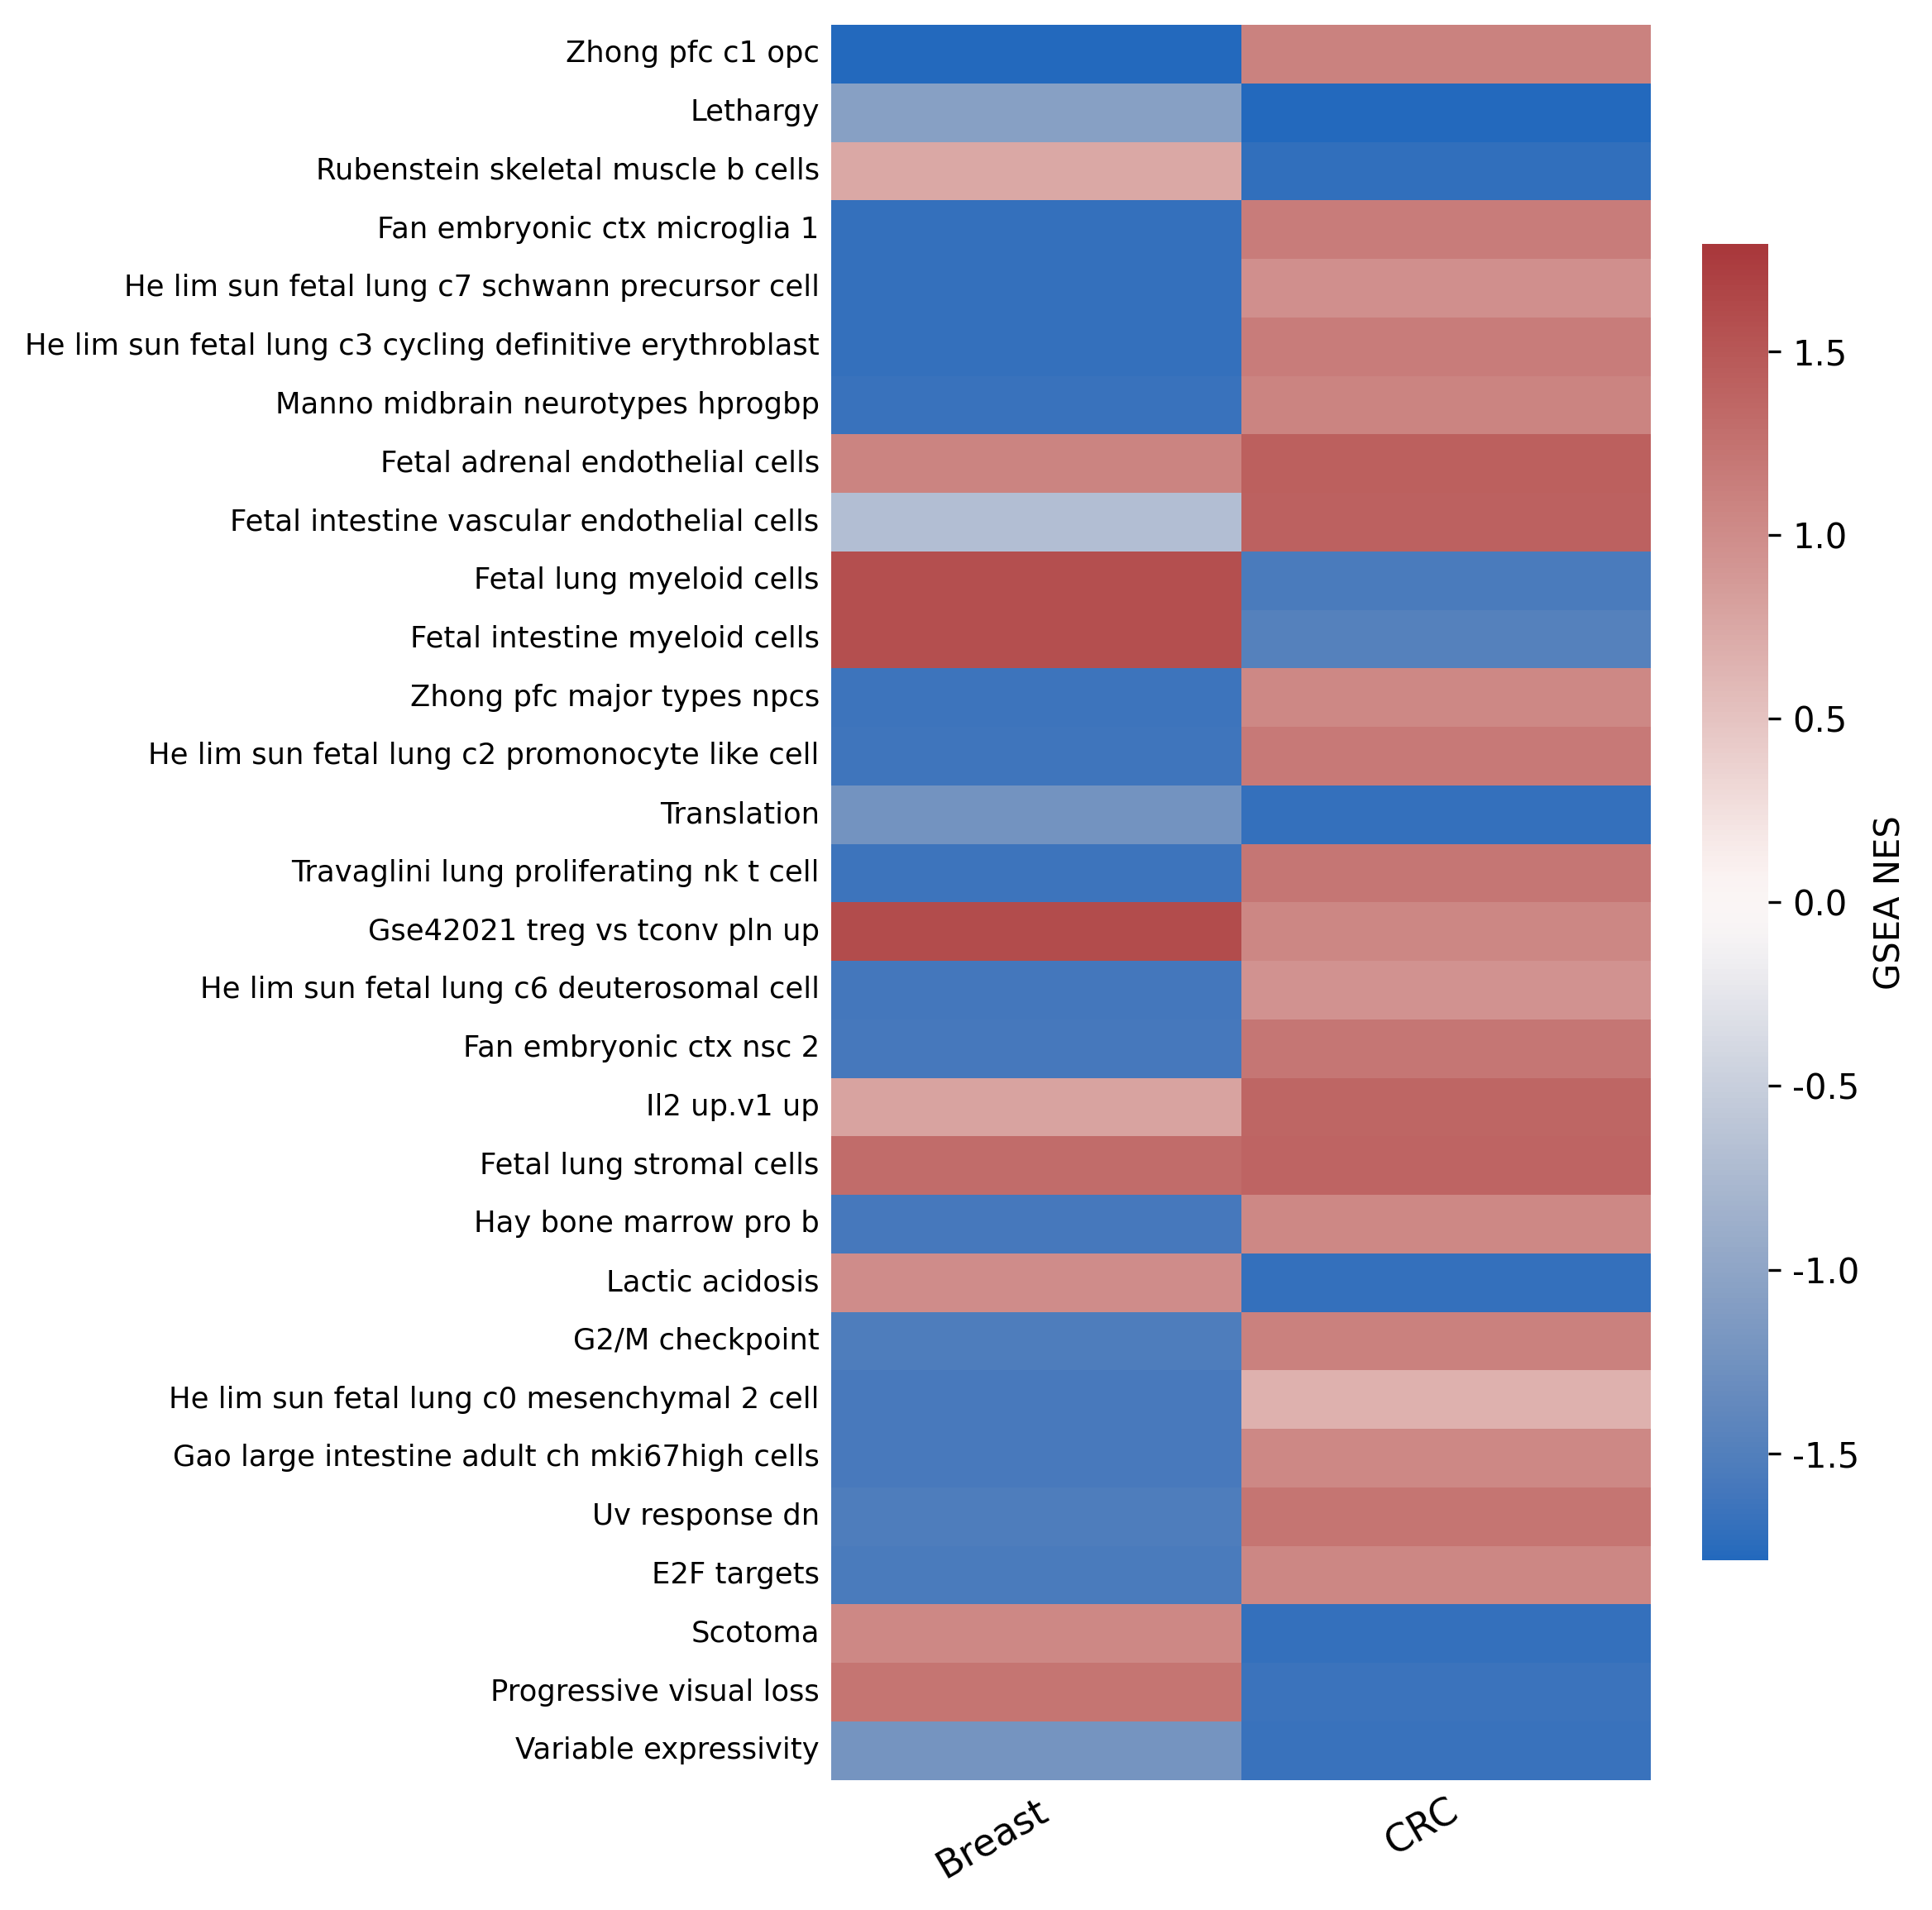


生成最终版图片: current_axis_genes_excluded


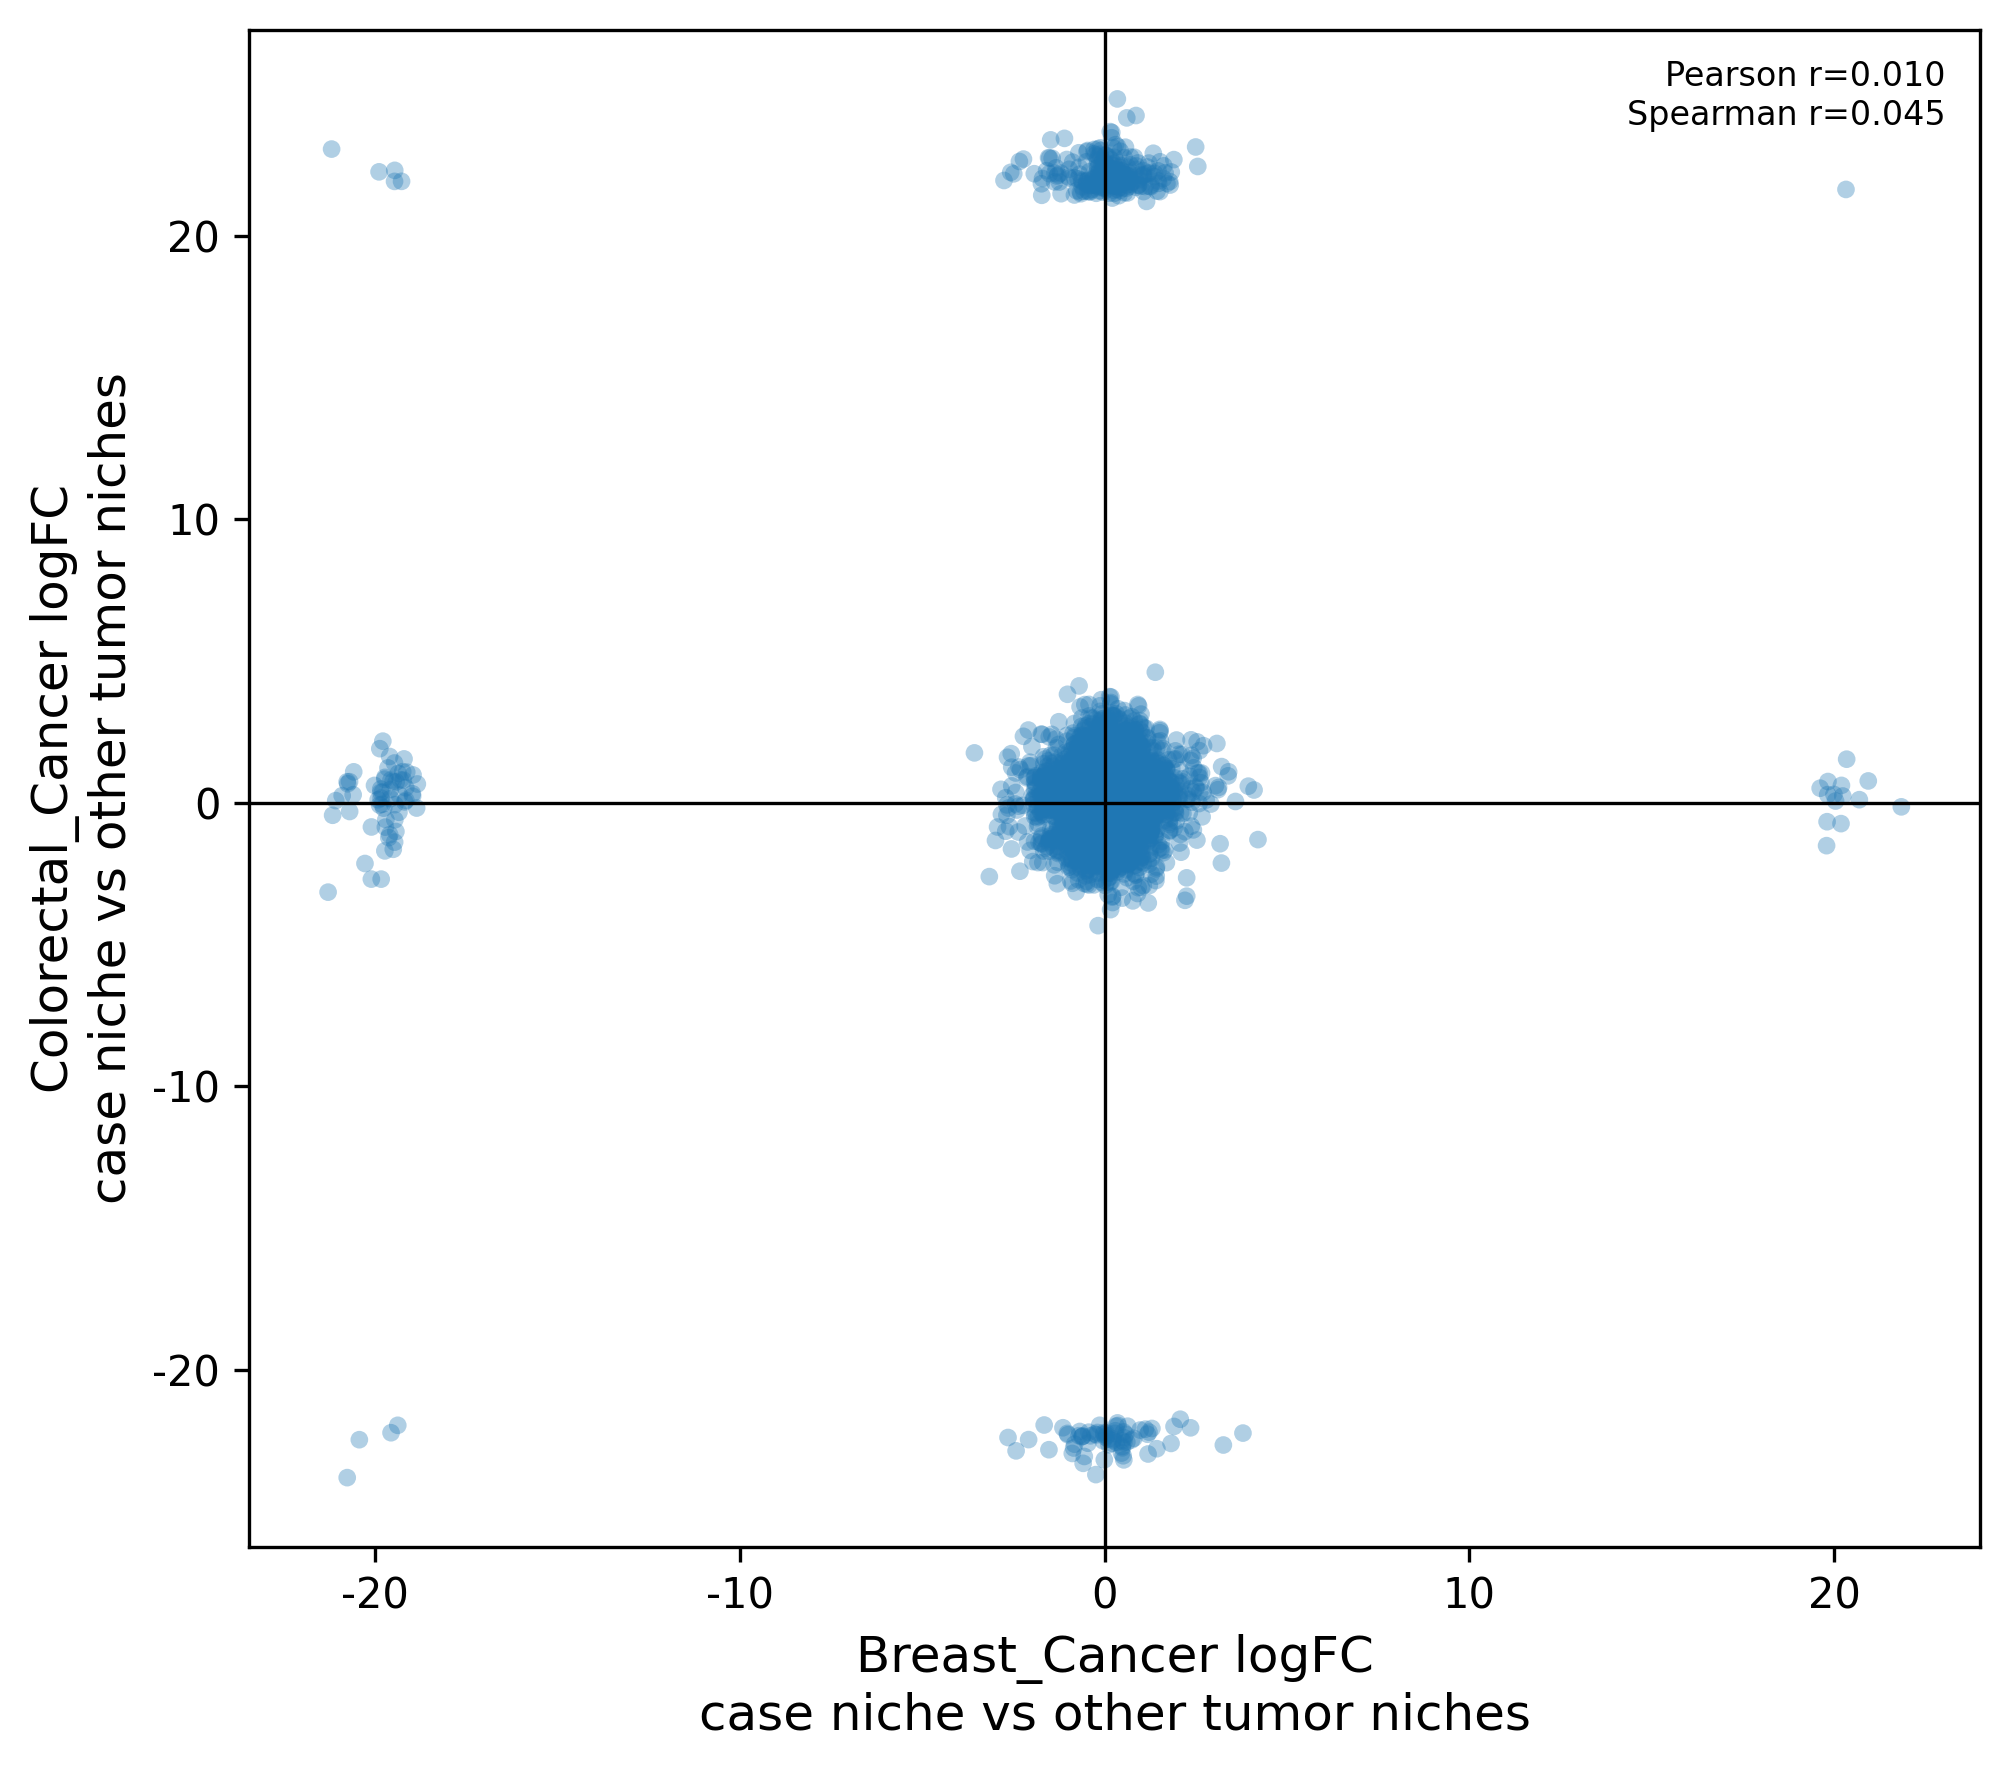

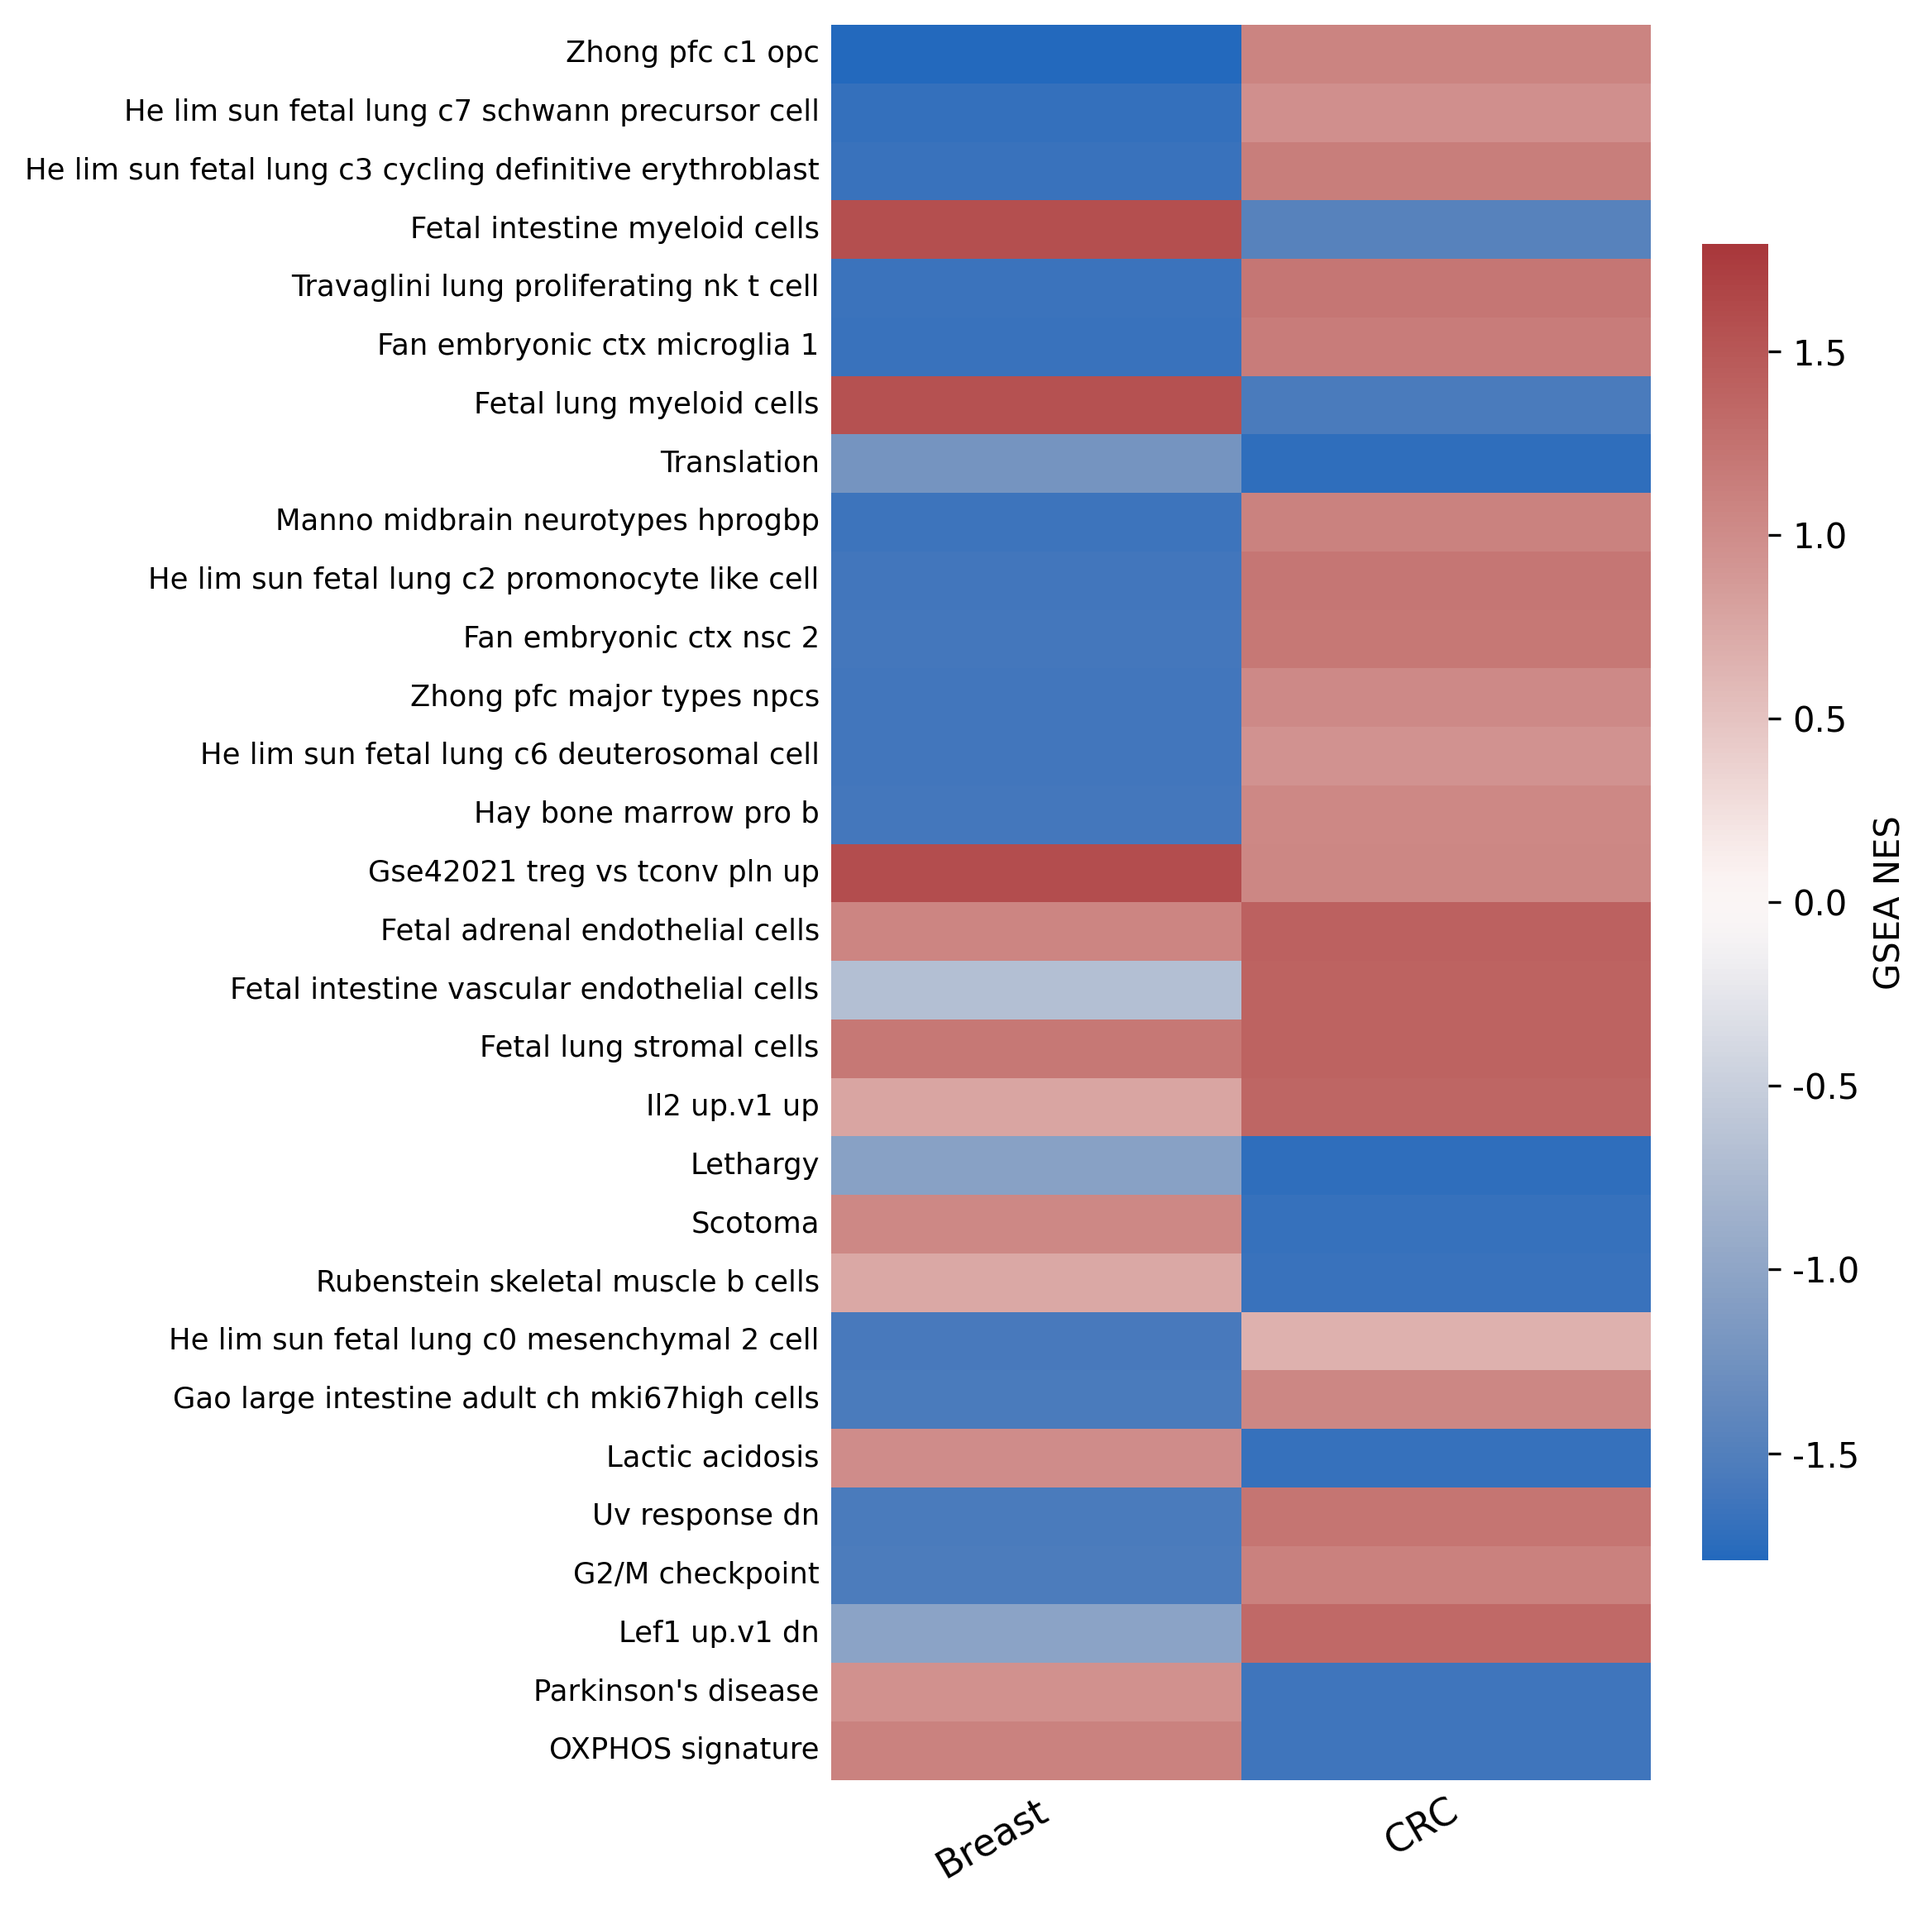


✅ 最终版图片保存目录: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/xin
 - /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/xin/DEG_logFC_scatter_all_genes_clean.png
 - /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/xin/GSEA_NES_heatmap_all_genes_clean.png
 - /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/xin/DEG_logFC_scatter_TMCN_genes_excluded_clean.png
 - /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/xin/GSEA_NES_heatmap_TMCN_genes_excluded_clean.png
 - /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/cross_cancer_niche_D

In [16]:
# =========================================================
# 新增单元格：重新生成最终版跨癌种散点图和 GSEA NES 热图
# 参考乳酸生态位 notebook 的最终修正版：
# 1) 散点图标题只保留 Pearson r / Spearman r；
# 2) 热图删除标题；
# 3) 热图左侧基因集名称改为论文常用的简洁名称，并自动去除重复基因集；
# 4) 避免长基因集名称出现省略号或自动换行；
# 5) 只重新保存图片，不重新计算 DEG / GSEA 表。
# =========================================================

from pathlib import Path
import re
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

try:
    import seaborn as sns
    _HAS_SEABORN_CLEAN = True
except Exception:
    _HAS_SEABORN_CLEAN = False

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ---------------------------------------------------------
# 0. 路径设置
# ---------------------------------------------------------
BASE_COMPARE_DIR = Path(
    "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/"
    "cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison"
)
FINAL_FIG_DIR = Path(
    "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/"
    "cross_cancer_niche_DEG/Mixed_Lactate_Glutamine_Breast_vs_CRC/cross_cancer_comparison/xin"
)
FINAL_FIG_DIR.mkdir(parents=True, exist_ok=True)

try:
    variants_to_plot = list(ANALYSIS_VARIANTS)
except NameError:
    variants_to_plot = ["all_genes", "TMCN_genes_excluded", "current_axis_genes_excluded"]

try:
    dataset_names_clean = list(DATASETS.keys())
except NameError:
    dataset_names_clean = ["Breast_Cancer", "Colorectal_Cancer"]

if len(dataset_names_clean) != 2:
    raise ValueError("当前代码只适用于两个癌种之间的比较。")

name_a, name_b = dataset_names_clean
short_name_map = {
    "Breast_Cancer": "Breast",
    "Colorectal_Cancer": "CRC",
    "Prostate_Cancer": "Prostate",
    "Pancreatic_Cancer": "Pancreas",
    "Lung_Cancer": "Lung",
}
short_a = short_name_map.get(name_a, name_a.replace("_", " "))
short_b = short_name_map.get(name_b, name_b.replace("_", " "))

# ---------------------------------------------------------
# 1. 基因集名称简化函数
# ---------------------------------------------------------
TERM_PREFIXES = [
    "HALLMARK_", "REACTOME_", "KEGG_", "GOBP_", "GOCC_", "GOMF_",
    "HP_", "WP_", "BIOCARTA_", "PID_", "NABA_", "C6_", "C7_", "C8_", "DESCARTES_",
]

MANUAL_TERM_LABELS = {
    # Mitochondria / respiration
    "AEROBIC_RESPIRATION_AND_RESPIRATORY_ELECTRON_TRANSPORT": "Aerobic respiration / ETC",
    "RESPIRATORY_ELECTRON_TRANSPORT": "Respiratory electron transport",
    "ELECTRON_TRANSPORT_CHAIN_OXPHOS_SYSTEM_IN_MITOCHONDRIA": "Mitochondrial ETC / OXPHOS",
    "OXIDATIVE_PHOSPHORYLATION": "Oxidative phosphorylation",
    "COMPLEX_IV_ASSEMBLY": "Complex IV assembly",
    "MITOCHONDRIAL_COMPLEX_I_ASSEMBLY_MODEL_OXPHOS_SYSTEM": "Mitochondrial complex I assembly",
    "MITOCHONDRIAL_TRANSLATION": "Mitochondrial translation",
    "MITOCHONDRIAL_PROTEIN_DEGRADATION": "Mitochondrial protein degradation",
    "ABNORMALITY_OF_THE_MITOCHONDRION": "Mitochondrial abnormality",
    "MITOCHONDRIAL_RESPIRATORY_CHAIN_COMPLEX_ASSEMBLY": "Respiratory chain assembly",
    "RESPIRATORY_CHAIN_COMPLEX_ASSEMBLY": "Respiratory chain assembly",
    "ATP_SYNTHESIS_COUPLED_ELECTRON_TRANSPORT": "ATP-coupled electron transport",

    # ECM / invasion
    "ASSEMBLY_OF_COLLAGEN_FIBRILS_AND_OTHER_MULTIMERIC_STRUCTURES": "Collagen fibril assembly",
    "EXTRACELLULAR_MATRIX_ORGANIZATION": "ECM organization",
    "DEGRADATION_OF_THE_EXTRACELLULAR_MATRIX": "ECM degradation",
    "COLLAGEN_FORMATION": "Collagen formation",
    "COLLAGEN_DEGRADATION": "Collagen degradation",
    "EXTERNAL_ENCAPSULATING_STRUCTURE": "External encapsulating structure",
    "ELASTIC_FIBRE_FORMATION": "Elastic fiber formation",
    "INTEGRIN_CELL_SURFACE_INTERACTIONS": "Integrin cell-surface interaction",
    "EPITHELIAL_MESENCHYMAL_TRANSITION": "EMT",
    "ANGIOGENESIS": "Angiogenesis",
    "VASCULATURE_DEVELOPMENT": "Vasculature development",
    "FETAL_ADRENAL_VASCULAR_ENDOTHELIAL_CELLS": "Fetal adrenal endothelial cells",
    "ADRENAL_VASCULAR_ENDOTHELIAL_CELLS": "Adrenal endothelial cells",
    "VASCULAR_ENDOTHELIAL_CELLS": "Endothelial cells",

    # Transport / metabolism
    "PROTON_TRANSMEMBRANE_TRANSPORT": "Proton transmembrane transport",
    "PROTON_TRANSMEMBRANE_TRANSPORTER_ACTIVITY": "Proton transmembrane transport",
    "ACTIVE_MONOATOMIC_ION_TRANSMEMBRANE_TRANSPORTER_ACTIVITY": "Ion transmembrane transport",
    "PRIMARY_ACTIVE_TRANSMEMBRANE_TRANSPORTER_ACTIVITY": "Primary active transport",
    "AMINO_ACID_TRANSPORT": "Amino acid transport",
    "ORGANIC_ACID_TRANSPORT": "Organic acid transport",
    "CARBOXYLIC_ACID_TRANSPORT": "Carboxylic acid transport",
    "GLUTAMINE_FAMILY_AMINO_ACID_METABOLIC_PROCESS": "Glutamine-family amino acid metabolism",
    "CELLULAR_AMINO_ACID_METABOLIC_PROCESS": "Cellular amino acid metabolism",
    "ALPHA_AMINO_ACID_METABOLIC_PROCESS": "Amino acid metabolism",
    "LACTIC_ACIDOSIS": "Lactic acidosis",
    "ABNORMAL_CSF_LACTATE_CONCENTRATION": "CSF lactate elevation",
    "ABNORMAL_CSF_METABOLITE_CONCENTRATION": "CSF metabolite abnormality",
    "ABNORMAL_CIRCULATING_AMINO_ACID_CONCENTRATION": "Circulating amino acid abnormality",

    # Proliferation / signaling
    "KRAS_SIGNALING_DN": "KRAS signaling down",
    "KRAS_SIGNALING_UP": "KRAS signaling up",
    "KRAS.600_UP.V1_DN": "KRAS oncogenic signature down",
    "COAGULATION": "Coagulation",
    "CELL_CYCLE": "Cell cycle",
    "G2M_CHECKPOINT": "G2/M checkpoint",
    "E2F_TARGETS": "E2F targets",
    "MYC_TARGETS_V1": "MYC targets v1",
    "MYC_TARGETS_V2": "MYC targets v2",
    "MITOTIC_SPINDLE": "Mitotic spindle",
    "DNA_REPAIR": "DNA repair",
    "HYPOXIA": "Hypoxia",
    "INFLAMMATORY_RESPONSE": "Inflammatory response",
    "TNFA_SIGNALING_VIA_NFKB": "TNFα/NFκB signaling",
    "IL6_JAK_STAT3_SIGNALING": "IL6/JAK/STAT3 signaling",

    # Translation / ribosome
    "EUKARYOTIC_TRANSLATION_ELONGATION": "Translation elongation",
    "PEPTIDE_CHAIN_ELONGATION": "Peptide-chain elongation",
    "TRANSLATION": "Translation",
    "RIBOSOME": "Ribosome",
    "RIBOSOMAL_SUBUNIT": "Ribosomal subunit",
    "SRP_DEPENDENT_COTRANSLATIONAL_PROTEIN_TARGETING_TO_MEMBRANE": "SRP-dependent protein targeting",
    "NONSENSE_MEDIATED_DECAY_NMD": "Nonsense-mediated decay",

    # Phenotype terms often appearing in MSigDB/HP
    "PIGMENTARY_RETINOPATHY": "Pigmentary retinopathy",
    "ABNORMAL_RETINAL_PIGMENTATION": "Retinal pigmentation abnormality",
    "SCOTOMA": "Scotoma",
    "ENCEPHALOPATHY": "Encephalopathy",
    "ACTION_TREMOR": "Action tremor",
    "PARKINSONS_DISEASE": "Parkinson's disease",
}

SPECIAL_CONTAINS_LABELS = [
    ("DESCARTES_FETAL_ADRENAL_VASCULAR_ENDOTHELIAL_CELLS", "Fetal adrenal endothelial cells"),
    ("FETAL_ADRENAL_VASCULAR_ENDOTHELIAL_CELLS", "Fetal adrenal endothelial cells"),
    ("GARCIA_PINERES_PBMC_HPV_16_L1_VLP", "HPV VLP vaccine response"),
    ("OXPHOS", "OXPHOS signature"),
]

ACRONYM_FIXES = {
    "Ecm": "ECM",
    "Etc": "ETC",
    "Oxphos": "OXPHOS",
    "Kras": "KRAS",
    "Dna": "DNA",
    "Rna": "RNA",
    "Atp": "ATP",
    "Nadh": "NADH",
    "Csf": "CSF",
    "Hpv": "HPV",
    "Vlp": "VLP",
    "Emt": "EMT",
    "Jak": "JAK",
    "Stat": "STAT",
    "Nfkb": "NFκB",
}


def _strip_term_prefix(term):
    """去掉 collection 和 MSigDB 前缀，返回用于匹配的核心 term。"""
    x = str(term)
    if "::" in x:
        x = x.split("::")[-1]
    x = x.strip()
    for p in TERM_PREFIXES:
        if x.upper().startswith(p):
            x = x[len(p):]
            break
    return x


def make_paper_style_gene_set_name(term):
    """将 MSigDB term 转为简洁、论文图中常用的基因集名称。"""
    core = _strip_term_prefix(term)
    key = core.upper()

    for pattern, label in SPECIAL_CONTAINS_LABELS:
        if pattern in key:
            return label

    if key in MANUAL_TERM_LABELS:
        return MANUAL_TERM_LABELS[key]

    label = core.replace("_", " ").replace("-", " ").strip()
    label = re.sub(r"\s+", " ", label)
    label = label.lower().capitalize()

    # 恢复常见缩写
    for wrong, right in ACRONYM_FIXES.items():
        label = re.sub(rf"\b{wrong}\b", right, label)

    # 不使用省略号，也不自动换行；如果少数名称过长，优先通过上方手动映射压缩。
    label = label.replace("\n", " ").strip()
    label = re.sub(r"\s+", " ", label)
    return label


def _get_numeric_series(df, col):
    return pd.to_numeric(df[col], errors="coerce")

# ---------------------------------------------------------
# 2. 重新绘制 DEG logFC 散点图
# ---------------------------------------------------------
def redraw_clean_deg_scatter(variant_name):
    in_csv = BASE_COMPARE_DIR / variant_name / f"DEG_cross_cancer_merged_{variant_name}.csv"
    if not in_csv.exists():
        print(f"⚠️ 未找到 DEG merged 文件，跳过: {in_csv}")
        return None

    df = pd.read_csv(in_csv)

    x_col = f"logfoldchanges_{name_a}"
    y_col = f"logfoldchanges_{name_b}"

    if x_col not in df.columns or y_col not in df.columns:
        lfc_cols = [c for c in df.columns if c.startswith("logfoldchanges_")]
        if len(lfc_cols) < 2:
            print(f"⚠️ {variant_name}: 找不到两个 logFC 列，跳过散点图。")
            return None
        x_col, y_col = lfc_cols[:2]

    plot_df = df[[x_col, y_col]].copy()
    plot_df[x_col] = _get_numeric_series(plot_df, x_col)
    plot_df[y_col] = _get_numeric_series(plot_df, y_col)
    plot_df = plot_df.dropna()

    if len(plot_df) < 3:
        print(f"⚠️ {variant_name}: 有效点数不足，跳过散点图。")
        return None

    pearson_r, _ = pearsonr(plot_df[x_col], plot_df[y_col])
    spearman_r, _ = spearmanr(plot_df[x_col], plot_df[y_col])

    fig, ax = plt.subplots(figsize=(6.8, 6), dpi=300)

    ax.scatter(
        plot_df[x_col],
        plot_df[y_col],
        s=18,
        alpha=0.35,
        edgecolors="none"
    )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)

    ax.set_xlabel(
        f"{name_a} logFC\ncase niche vs other tumor niches",
        fontsize=12
    )
    ax.set_ylabel(
        f"{name_b} logFC\ncase niche vs other tumor niches",
        fontsize=12
    )

    # 不显示标题
    ax.set_title("")

    # 将 Pearson / Spearman 放到图内右上角，避免压缩横轴
    ax.text(
        0.98, 0.98,
        f"Pearson r={pearson_r:.3f}\nSpearman r={spearman_r:.3f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        color="black",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.65,
            pad=2
        )
    )

    ax.tick_params(axis="both", labelsize=10)

    # 不再给右侧单独留白，主图不会被压缩
    plt.tight_layout()

    out_png = FINAL_FIG_DIR / f"DEG_logFC_scatter_{variant_name}_clean.png"
    out_pdf = FINAL_FIG_DIR / f"DEG_logFC_scatter_{variant_name}_clean.pdf"

    fig.savefig(out_png, dpi=600, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    plt.show()

    return out_png

# ---------------------------------------------------------
# 3. 重新绘制 GSEA NES 热图
# ---------------------------------------------------------
def redraw_clean_gsea_heatmap(variant_name, top_n_terms=40):
    in_csv = BASE_COMPARE_DIR / variant_name / f"GSEA_cross_cancer_merged_{variant_name}.csv"
    if not in_csv.exists():
        print(f"⚠️ 未找到 GSEA merged 文件，跳过: {in_csv}")
        return None

    df = pd.read_csv(in_csv)

    nes_a = f"NES_{name_a}"
    nes_b = f"NES_{name_b}"
    fdr_a = f"FDR_{name_a}"
    fdr_b = f"FDR_{name_b}"

    if nes_a not in df.columns or nes_b not in df.columns:
        nes_cols = [c for c in df.columns if c.startswith("NES_")]
        if len(nes_cols) < 2:
            print(f"⚠️ {variant_name}: 找不到两个 NES 列，跳过热图。")
            return None
        nes_a, nes_b = nes_cols[:2]

    for c in [nes_a, nes_b, fdr_a, fdr_b]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    if "abs_max_NES" not in df.columns:
        df["abs_max_NES"] = df[[nes_a, nes_b]].abs().max(axis=1)
    else:
        df["abs_max_NES"] = pd.to_numeric(df["abs_max_NES"], errors="coerce")

    if "min_FDR" not in df.columns:
        fdr_cols = [c for c in [fdr_a, fdr_b] if c in df.columns]
        if len(fdr_cols) > 0:
            df["min_FDR"] = df[fdr_cols].min(axis=1)
        else:
            df["min_FDR"] = 1.0
    else:
        df["min_FDR"] = pd.to_numeric(df["min_FDR"], errors="coerce")

    # 构建 display term：collection::Term，然后转成论文式短名称
    if "collection" in df.columns and "Term" in df.columns:
        df["raw_display_term"] = df["collection"].astype(str) + "::" + df["Term"].astype(str)
    elif "Term" in df.columns:
        df["raw_display_term"] = df["Term"].astype(str)
    else:
        print(f"⚠️ {variant_name}: 找不到 Term 列，跳过热图。")
        return None

    df["paper_term"] = df["raw_display_term"].apply(make_paper_style_gene_set_name)

    # 先按照显著性和绝对 NES 排序，再按简化后的名称去重。
    # 这样 Reactome / Curated_CP 中相同 term 只保留一个最优条目。
    selected = (
        df.dropna(subset=[nes_a, nes_b])
          .sort_values(["min_FDR", "abs_max_NES"], ascending=[True, False])
          .drop_duplicates(subset=["paper_term"], keep="first")
          .head(top_n_terms)
          .copy()
    )

    if len(selected) == 0:
        print(f"⚠️ {variant_name}: 没有可绘制的 GSEA term。")
        return None

    heatmap_df = selected.set_index("paper_term")[[nes_a, nes_b]].copy()
    heatmap_df.columns = [short_a, short_b]
    heatmap_df = heatmap_df.apply(pd.to_numeric, errors="coerce").dropna(how="all")

    # 对称色标，便于比较正/负 NES
    vmax = np.nanmax(np.abs(heatmap_df.values))
    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0
    vmin = -vmax

    # 最终版：左侧基因集名称不换行、不省略；少数长标签通过名称映射简化。
    heatmap_df.index = [str(x).replace("\n", " ").strip() for x in heatmap_df.index]
    heatmap_df.index = [re.sub(r"\s+", " ", x) for x in heatmap_df.index]

    # 根据左侧标签长度适度加宽画布，避免标签被挤压；行高保持紧凑。
    fig_h = max(4.2, 0.23 * len(heatmap_df) + 0.9)
    max_label_len = max([len(str(x)) for x in heatmap_df.index] + [0])
    fig_w = max(6.6, min(10.5, 4.6 + 0.055 * max_label_len))
    fig, ax = plt.subplots(figsize=(fig_w, fig_h), dpi=300)

    if _HAS_SEABORN_CLEAN:
        sns.heatmap(
            heatmap_df,
            cmap="vlag",
            center=0,
            vmin=vmin,
            vmax=vmax,
            linewidths=0,
            linecolor=None,
            cbar_kws={"label": "GSEA NES", "shrink": 0.75},
            ax=ax
        )
    else:
        im = ax.imshow(heatmap_df.values.astype(float), aspect="auto", vmin=vmin, vmax=vmax)
        ax.set_xticks(range(heatmap_df.shape[1]))
        ax.set_xticklabels(heatmap_df.columns)
        ax.set_yticks(range(heatmap_df.shape[0]))
        ax.set_yticklabels(heatmap_df.index)
        fig.colorbar(im, ax=ax, label="GSEA NES", shrink=0.75)

    # 删除标题，只保留热图主体和必要标签
    ax.set_title("")
    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=30,
        ha="right",
        rotation_mode="anchor",
        fontsize=11
    )
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=8.5)
    ax.tick_params(axis="both", length=0)

    plt.tight_layout()
    out_png = FINAL_FIG_DIR / f"GSEA_NES_heatmap_{variant_name}_clean.png"
    out_pdf = FINAL_FIG_DIR / f"GSEA_NES_heatmap_{variant_name}_clean.pdf"
    fig.savefig(out_png, dpi=600, bbox_inches="tight")
    fig.savefig(out_pdf, bbox_inches="tight")
    plt.show()
    return out_png

# ---------------------------------------------------------
# 4. 批量生成并保存
# ---------------------------------------------------------
saved_images = []
for variant_name in variants_to_plot:
    print("\n" + "=" * 90)
    print(f"生成最终版图片: {variant_name}")
    print("=" * 90)

    p1 = redraw_clean_deg_scatter(variant_name)
    if p1 is not None:
        saved_images.append(p1)

    p2 = redraw_clean_gsea_heatmap(variant_name, top_n_terms=30)
    if p2 is not None:
        saved_images.append(p2)

print("\n✅ 最终版图片保存目录:", FINAL_FIG_DIR)
for p in saved_images:
    print(" -", p)
